# Philippines News Headlines — Sentiment Analysis & Trend Monitoring

### End-to-end NLP machine-learning pipeline for an **unstructured CSV**

**Dataset:** `Philippines-News-Headlines-Dataset-for-Sentiment-Analysis.csv`  
**Raw schema:** `Date`, `Headlines`  
**Task:** Binary sentiment classification — **Positive / Negative** (headlines with a near-neutral tone are dropped rather than force-labelled)  
**Goal:** clean the raw archive, generate a transparent target label, explore media trends, train and evaluate supervised NLP models, interpret the final model, and package a simple live prediction interface.

> **Important limitation:** the supplied CSV has **no human-written sentiment labels**. The target is therefore created with a reproducible lexicon-style teacher rule using TextBlob polarity. Model scores measure agreement with these pseudo-labels, not agreement with human annotators. This limitation is discussed again in the Responsible AI and Conclusion sections.


## 1. Setup & reproducibility (B5, B6)

One seed controls random splitting and cross-validation. Package versions are recorded so the experiment can be reproduced. The notebook also writes two small reusable modules (`news_nlp_utils.py` and `news_predictor.py`) so the packaged pipeline does not depend on hidden notebook-only functions.

In [8]:
# ── Standard library imports ──────────────────────────────────────────────
import os
import sys
import json
import time
import random
import hashlib
import platform
import warnings
import datetime as dt
from pathlib import Path                      # cleaner, OS-agnostic file paths


# ── Data handling & plotting ──────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown  # render tables/markdown nicely in the notebook

# ── Modelling stack ────────────────────────────────────────────────────────
import sklearn
import joblib                                  # used later to save/load the trained pipeline to disk
from textblob import TextBlob                  # gives us a polarity score we use to CREATE the target label

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer   # applies different preprocessing to text vs. numeric columns
from sklearn.dummy import DummyClassifier       # "do-nothing" baseline model for comparison
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_recall_fscore_support,
    precision_recall_curve, average_precision_score, roc_auc_score,
    RocCurveDisplay, ConfusionMatrixDisplay
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV,
    learning_curve
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.svm import LinearSVC

# Silence noisy convergence/deprecation warnings so output stays readable.
warnings.filterwarnings('ignore')

# ── Reproducibility (B5) ───────────────────────────────────────────────────
SEED = 42        # one fixed seed used everywhere a random process happens
N_JOBS = 1        # kept at 1 for deterministic, notebook-safe parallelism
random.seed(SEED)
np.random.seed(SEED)

# Print environment versions so results can be reproduced on another machine.
print('Python      :', sys.version.split()[0])
print('pandas      :', pd.__version__)
print('numpy       :', np.__version__)
print('scikit-learn:', sklearn.__version__)
print('TextBlob    :', getattr(__import__('textblob'), '__version__', 'installed'))
print('joblib      :', joblib.__version__)
print('Seed        :', SEED)

Python      : 3.10.19
pandas      : 2.3.3
numpy       : 2.2.5
scikit-learn: 1.7.2
TextBlob    : installed
joblib      : 1.5.2
Seed        : 42


In [9]:
# Reusable helper module written to disk, so it can be imported both here and
# later from the standalone news_predictor.py inference wrapper (Section 18).
UTILS_PY = r"""
# news_nlp_utils.py - reusable helpers for the Philippines news sentiment pipeline.
from __future__ import annotations
import re
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

# List of engineered numeric/flag columns that get attached to every headline,
# in addition to the TF-IDF text features. This list is imported elsewhere
# (e.g. the ColumnTransformer) so the model always knows exactly which
# metadata columns to expect.
META_COLUMNS = [
    "char_count", "word_count", "unique_word_ratio", "exclamation_count",
    "question_count", "digit_ratio", "uppercase_ratio", "avg_word_length", "has_negative_domain_term"
]

# Words that signal a genuinely negative real-world topic even when the
# headline's wording is calm/factual (e.g. "Inflation hits new high" has no
# emotionally-loaded words, so TextBlob alone would miss it).
NEGATIVE_DOMAIN_TERMS = [
    'typhoon', 'flood', 'earthquake', 'landslide', 'disaster', 'evacuate',
    'corrupt', 'corruption', 'bribery', 'scandal', 'fraud', 'graft',
    'inflation', 'recession', 'layoff', 'unemployment', 'debt', 'deficit',
    'crash', 'accident', 'death', 'killed', 'dead', 'injured', 'victim',
    'protest', 'unrest', 'violence', 'crime', 'arrest', 'shooting',
    'congestion', 'delay', 'shortage', 'outbreak', 'lockdown', 'ban'
]
# Join the word list into a single regex pattern: word1|word2|word3|...
# so a single re.search() call can check for ANY of them at once.
_NEG_PATTERN = '|'.join(NEGATIVE_DOMAIN_TERMS)


def clean_headline(text: str) -> str:
    # Safe text normalization; keeps negation words and useful punctuation cues.
    # If text is missing (None), replace it with an empty string instead of crashing.
    text = "" if text is None else str(text)
    # Replace non-breaking space characters with normal spaces.
    text = text.replace("\xa0", " ")
    # Collapse any URL (http/https/www links) down to a single "URL" placeholder token,
    # since the exact link text carries no sentiment signal.
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    # Collapse repeated whitespace into single spaces, trim the ends, and lowercase
    # everything so "Rises" and "rises" are treated as the same word by TF-IDF.
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text


def build_meta_features(series: pd.Series) -> pd.DataFrame:
    # Create deterministic, row-wise headline metadata from raw text (used both
    # as extra model features and for several EDA visualizations above).
    rows = []
    # fillna("") handles any missing headlines safely; astype(str) guarantees
    # every value is a plain string before we start measuring it.
    for raw in series.fillna("").astype(str):
        # Split into individual words on whitespace.
        words = raw.split()
        n_words = len(words)
        # Precompute the lowercase version once, reused below for the keyword check.
        raw_lower = raw.lower()
        rows.append({
            # Total number of characters in the headline.
            "char_count": len(raw),
            # Total number of words in the headline.
            "word_count": n_words,
            # Fraction of words that are unique (max(n_words, 1) avoids divide-by-zero
            # on an empty headline).
            "unique_word_ratio": len(set(w.lower() for w in words)) / max(n_words, 1),
            # Count of "!" characters -- a rough proxy for sensationalized tone.
            "exclamation_count": raw.count("!"),
            # Count of "?" characters.
            "question_count": raw.count("?"),
            # Fraction of characters that are digits (e.g. dates, statistics).
            "digit_ratio": sum(ch.isdigit() for ch in raw) / max(len(raw), 1),
            # Fraction of characters that are uppercase (e.g. ALL-CAPS headlines).
            "uppercase_ratio": sum(ch.isupper() for ch in raw) / max(len(raw), 1),
            # Average word length; 0.0 for an empty headline instead of crashing on
            # an empty mean.
            "avg_word_length": np.mean([len(w) for w in words]) if words else 0.0,
            # 1 if the headline contains ANY of the negative-domain keywords, else 0.
            # bool(...) turns the regex match object (or None) into True/False,
            # and int(...) turns that into 1/0 so it behaves like the other numeric columns.
            "has_negative_domain_term": int(bool(re.search(_NEG_PATTERN, raw_lower))),
        })
    # Turn the list of per-row dictionaries into one DataFrame, keeping the same
    # row index as the input Series so it lines up correctly when concatenated later.
    return pd.DataFrame(rows, index=series.index)


class Winsorizer(BaseEstimator, TransformerMixin):
    # Clip numeric features to training-set quantile bounds (A3): learns the
    # bounds from fit() (training data only) and clips with them in transform().
    def __init__(self, lower=0.01, upper=0.99):
        # Lower/upper quantile cutoffs, e.g. 1st and 99th percentile by default.
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        # Force X into a float array so quantile math works cleanly.
        X = np.asarray(X, dtype=float)
        # Learn the clipping bounds ONLY from the data passed in here (training data),
        # so no information about the test set leaks into these thresholds.
        self.lower_ = np.nanquantile(X, self.lower, axis=0)
        self.upper_ = np.nanquantile(X, self.upper, axis=0)
        return self  # scikit-learn convention: fit() must return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        # Clamp every value into [lower_, upper_] using the bounds learned in fit().
        return np.clip(X, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        # Clipping doesn't add/remove/rename columns, so output names = input names.
        # Without this method, scikit-learn's pipeline machinery raises an error
        # once a Winsorizer is used inside it -- this is the fix for that.
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        # Fallback if no names were given: just number the columns x0, x1, ...
        n = getattr(self, "lower_", np.array([])).shape[0]
        return np.asarray([f"x{i}" for i in range(n)], dtype=object)


def validate_headline(text: str, max_chars: int = 500) -> str:
    # Reject a missing (None) headline outright.
    if text is None:
        raise ValueError("Headline cannot be empty.")
    # Trim whitespace, then reject a headline that's blank after trimming.
    text = str(text).strip()
    if not text:
        raise ValueError("Headline cannot be empty.")
    # Reject headlines that are unreasonably long (guards the live prediction UI
    # against pasted-in walls of text).
    if len(text) > max_chars:
        raise ValueError(f"Headline is too long. Maximum supported length is {max_chars} characters.")
    return text
"""
# Write the module source code above out to an actual .py file on disk, so it
# can be imported normally (both here, and later by news_predictor.py).
Path('news_nlp_utils.py').write_text(UTILS_PY, encoding='utf-8')

# Make sure the current working directory is on Python's import search path,
# so "from news_nlp_utils import ..." below can actually find the file we just wrote.
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

# Import everything the rest of the notebook needs from the newly written module.
from news_nlp_utils import clean_headline, build_meta_features, Winsorizer, META_COLUMNS, validate_headline

# Confirms the module was written and imported successfully -- if this print
# doesn't appear, something above failed silently and later cells will error.
print('Helper module ready:', Path('news_nlp_utils.py').resolve())

Helper module ready: C:\Users\ArizLuiz\Documents\Electives\news_nlp_utils.py


## 2. Problem definition & target identification (A1)

### Business / analytical question

Can raw media headlines be automatically categorized into **Positive or Negative**
sentiment so that large news archives can be monitored at scale?

### Target variable

The dataset contains only raw `Headlines` and `Date`, so there is no observed target column. A
reproducible teacher rule is used, and this is now a **binary** target:

- `Positive` if **TextBlob polarity > +0.05**
- `Negative` if **TextBlob polarity < -0.05**
- otherwise, the headline is **dropped** from the dataset entirely

TextBlob polarity ranges from -1 to +1. Earlier versions of this notebook kept the near-zero
"dead zone" as a third `Neutral` class, but that class was small, hard to distinguish from the
other two, and pulled every metric (and every chart) toward a bias that wasn't really about
Positive-vs-Negative sentiment at all. Dropping those ambiguous headlines instead of guessing at
them gives a cleaner, more confidently-labeled binary target.

**Context-override rule:** TextBlob is a general-purpose lexicon tool and scores "growth"/
"magnitude" words (*rises, hits new high, surges, worsening*) as positive regardless of what is
doing the growing. This means headlines like "Inflation hits new high" were being auto-labeled
Positive even though rising inflation is bad news. Before the polarity threshold is applied, any
headline containing a growth word alongside a noun that is inherently negative when it grows
(*inflation, unemployment, debt, crime, deaths, cases,* etc.) is force-labeled `Negative`,
overriding TextBlob's raw score. This targets a specific, explainable failure mode in the
pseudo-labeling tool rather than blindly re-weighting the whole dataset — see Section 4 for the
implementation and the count of headlines this override affected.

**Why this matters:** this creates a usable supervised-learning target, but the labels are
**pseudo-labels**. A human-annotated dataset would be required for a strong claim about
real-world sentiment accuracy.

### Target variable — in one line

> **Target column: `Sentiment Category`** (2 classes: `Positive`, `Negative`), predicted from the `Headlines` text.


In [10]:
from pathlib import Path
import pandas as pd

FILENAME = "Philippines-News-Headlines-Dataset-for-Sentiment-Analysis.csv"

CANDIDATE_PATHS = [
    Path("Datasets") / FILENAME,   # your VS Code folder
    Path("../Datasets") / FILENAME,
    Path("/kaggle/input/philippines-news-headlines-dataset-for-sentiment-analysis") / FILENAME,
    Path("/kaggle/input/datasets/philippines-news-headlines-dataset-for-sentiment-analysis") / FILENAME,
]

DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)

# Fallback: search for any matching CSV in the usual folders
if DATA_PATH is None:
    for root in [Path("Datasets"), Path("../Datasets"), Path("/kaggle/input")]:
        if root.exists():
            matches = [p for p in root.rglob("*.csv") if "philippines-news-headlines" in p.name.lower()]
            if matches:
                DATA_PATH = matches[0]
                break

if DATA_PATH is None:
    raise FileNotFoundError(
        f"CSV not found. Current folder is {Path.cwd()}. "
        "Check that the Datasets folder is next to this notebook."
    )

raw = pd.read_csv(DATA_PATH)
source_path = DATA_PATH   # used later when the notebook hashes the dataset

print(f"Loaded: {source_path}")
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
display(raw.head(8))

Loaded: Datasets\Philippines-News-Headlines-Dataset-for-Sentiment-Analysis.csv
Raw shape: 65,006 rows x 2 columns


,Date,Headlines
0,5/14/2023,Miranda's doctrine.
1,5/14/2023,US equity firm looks to more investments in PH.
2,5/14/2023,Nickel Asia Corp Announces its Notice of Annua...
3,5/14/2023,DoF reconvenes the Green Force.
4,5/14/2023,Cebu MSMEs get training from DTI.
5,5/14/2023,Trade Chief Pascual calls for 'soft connectivi...
6,5/14/2023,Stay-at-home moms' contribution beyond paycheck.
7,5/14/2023,Getting ready for developing secure EV.


## 3. Data-quality audit & missing values (A2)

The audit checks true nulls, blank strings, invalid dates, exact duplicate records, and basic text-length anomalies. Duplicated **date + headline** rows are removed. Repeated headlines on different dates are kept because a headline can legitimately recur in a time-series archive.

In [11]:
# Build one summary table: dtype, missing count/%, and unique-value count per column.
audit = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'missing': raw.isna().sum(),
    'missing_%': (raw.isna().mean() * 100).round(2),
    'n_unique': raw.nunique(dropna=True),
})

display(audit)

# A few extra "hidden missingness" checks beyond pandas' isna():
print('Exact duplicate rows:', int(raw.duplicated().sum()))                                           # fully identical rows
print('Blank headline rows :', int(raw['Headlines'].astype(str).str.strip().eq('').sum()))            # "" or whitespace-only text
print('Date parse failures  :', int(pd.to_datetime(raw['Date'], errors='coerce').isna().sum()))       # unparseable date strings
print('Duplicate headline texts (regardless of date):', int(raw['Headlines'].astype(str).str.strip().duplicated().sum()))

,dtype,missing,missing_%,n_unique
Date,object,0,0.0,3221
Headlines,object,0,0.0,64353


Exact duplicate rows: 223
Blank headline rows : 0
Date parse failures  : 0
Duplicate headline texts (regardless of date): 663


### Cleaning decisions summary

| Raw issue | Action | Reason |
|---|---|---|
| `Date` stored as object text | Convert to datetime | Enables time-based trend analysis |
| Leading/trailing/duplicate whitespace | Strip + normalize | Consistent text representation |
| Empty/invalid rows | Drop only if present | Cannot contribute usable information |
| Exact duplicate `Date + Headline` | Remove | Prevents duplicated observations from overweighting patterns |
| Same headline on different dates | Keep | It may represent a real repeated publication event |
| Text stopwords | **Not aggressively removed** | Words such as “not”, “no”, and “never” can carry sentiment |
| URLs | Replace with token `URL` | Reduces noisy unique strings while retaining the presence of a link |

In [12]:
# Define a list of domain-specific negative keywords (e.g., natural disasters, crimes, economic issues)
# that often convey negative news sentiment without using traditional sentiment adjectives like "bad" or "terrible".
# --- Cleaning decisions (safe before split: no model parameters are fitted here) ---
df = raw.copy()
df['Date_dt'] = pd.to_datetime(df['Date'], errors='coerce')                           # parse text date -> real datetime
df['Headlines'] = df['Headlines'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()  # collapse repeated whitespace

# Drop rows where the date failed to parse OR the headline is blank; these carry no signal.
df = df.loc[df['Date_dt'].notna() & df['Headlines'].ne('')].copy()

before_dupes = len(df)
df = df.drop_duplicates(subset=['Date_dt', 'Headlines']).reset_index(drop=True)  # remove exact re-publications
removed_dupes = before_dupes - len(df)

df['text'] = df['Headlines'].map(clean_headline)          # model-ready, lower-cased/normalized text
meta = build_meta_features(df['Headlines'])                # engineered numeric features (length, punctuation, etc.)
df = pd.concat([df, meta], axis=1)

NEGATIVE_DOMAIN_TERMS = [
    'typhoon', 'flood', 'earthquake', 'landslide', 'disaster', 'evacuate',
    'corrupt', 'corruption', 'bribery', 'scandal', 'fraud', 'graft',
    'inflation', 'recession', 'layoff', 'unemployment', 'debt', 'deficit',
    'crash', 'accident', 'death', 'killed', 'dead', 'injured', 'victim',
    'protest', 'unrest', 'violence', 'crime', 'arrest', 'shooting',
    'congestion', 'delay', 'shortage', 'outbreak', 'lockdown', 'ban'
]

# Join all terms in the list with the regex OR operator ('|') to construct a single regular expression pattern.
# Resulting pattern format: 'typhoon|flood|earthquake|...' (matches any string containing at least one term).
_neg_pattern = '|'.join(NEGATIVE_DOMAIN_TERMS)

# 1. df['Headlines']: Selects the 'Headlines' pandas Series (column) from the DataFrame `df`.
# 2. .str.lower(): Converts all string values in the column to lowercase to enable case-insensitive matching.
# 3. .str.contains(_neg_pattern, regex=True): Checks each headline string against the regex pattern, returning True if any term is found, else False.
# 4. .astype(int): Converts the resulting boolean Series (True/False) into binary integer flags (1 for True, 0 for False).
# 5. df['has_negative_domain_term'] = ...: Assigns the binary series as a new column named 'has_negative_domain_term' in the DataFrame `df`.
df['has_negative_domain_term'] = df['Headlines'].str.lower().str.contains(_neg_pattern, regex=True).astype(int)

## 4. Target generation and class balance (A1, A6)

The teacher-label score is generated from the **raw headline text only**. It is not learned from the train/test data and therefore does not fit parameters on the test set.

In [13]:
import re

import numpy as np
import pandas as pd
from textblob import TextBlob

# Define a raw regular expression string matching words indicative of "growth", "rising", or "increasing".
# `\b` asserts a word boundary, while `|` acts as an OR operator to match any word listed inside the group.
GROWTH_WORDS = r'\b(rise|rises|rising|risen|increase|increases|increasing|surge|surges|surging|hit|hits|hitting|soar|soars|soaring|jump|jumps|jumping|climb|climbs|worsen|worsens|worsening|new high|higher)\b'

# Define a raw regular expression string matching negative nouns/concepts (where "growth" represents a bad outcome).
# `\b` ensures whole-word matching to prevent false positives (e.g., matching "taxes" inside another word).
NEGATIVE_GROWTH_NOUNS = r'\b(inflation|unemployment|debt|poverty|deficit|crime|corruption|cases|deaths|fatalities|prices|fees|fares|taxes|congestion|tensions|casualties|defeat|defeats|Crash|Crashed|Crashes|cuts)\b'


# Define a helper function that takes a text string and returns TextBlob's sentiment polarity score.
def teacher_polarity(text: str) -> float:
    # TextBlob(text).sentiment.polarity calculates a float value between -1.0 (very negative) and +1.0 (very positive); cast explicitly to float
    return float(TextBlob(text).sentiment.polarity)


# Apply the `teacher_polarity` function to every headline in the 'Headlines' column using pandas `.map()` and assign the result to a new column
df['teacher_polarity'] = df['Headlines'].map(teacher_polarity)

# Convert all text in the 'Headlines' column to lowercase for case-insensitive regex matching
text_lower = df['Headlines'].str.lower()

# Create a Boolean Series (True/False) checking if each headline contains any word from the GROWTH_WORDS regex pattern
has_growth_word = text_lower.str.contains(GROWTH_WORDS, regex=True)

# Create a Boolean Series (True/False) checking if each headline contains any noun from the NEGATIVE_GROWTH_NOUNS regex pattern
has_negative_noun = text_lower.str.contains(NEGATIVE_GROWTH_NOUNS, regex=True)

# Combine both Boolean conditions with element-wise AND (&) operator.
# Evaluates to True ONLY if a headline contains BOTH a growth word AND a negative noun (e.g., "inflation rises")
context_override = has_growth_word & has_negative_noun

# Assign sentiment categories conditionally using `np.select(condlist, choicelist, default)`:
# 1. If context_override is True -> force label to 'Negative'
# 2. Else if polarity > 0.05 -> label as 'Positive'
# 3. Else if polarity < -0.05 -> label as 'Negative'
# 4. Otherwise (neutral zone between -0.05 and 0.05) -> label as 'DROP'
df['Sentiment Category'] = np.select(
    [
        context_override,
        df['teacher_polarity'] > 0.05,
        df['teacher_polarity'] < -0.05,
    ],
    ['Negative', 'Positive', 'Negative'],
    default='DROP',
)

# Store the total number of rows in the DataFrame before dropping neutral samples
before_binary = len(df)

# Filter out rows labeled as 'DROP' using `.loc[]` and reset the DataFrame index to maintain clean integer indexing (0, 1, 2...)
df = df.loc[df['Sentiment Category'] != 'DROP'].reset_index(drop=True)

# Calculate how many neutral headlines were dropped from the dataset
dropped_neutral_zone = before_binary - len(df)

# Define the canonical ordered list of target categories
TARGET_ORDER = ['Negative', 'Positive']

# Convert the 'Sentiment Category' column into an ordered pandas Categorical type based on TARGET_ORDER
df['Sentiment Category'] = pd.Categorical(
    df['Sentiment Category'], categories=TARGET_ORDER, ordered=True
)

# Output the total count of headlines that were overridden to 'Negative' due to the growth + negative noun rule
print(
    'Context-override headlines forced to Negative:'
    f' {context_override.sum():,}'
)

# Compute value counts for each category, reindexing to ensure both 'Negative' and 'Positive' appear in TARGET_ORDER
balance = df['Sentiment Category'].value_counts().reindex(TARGET_ORDER)

# Create and display a summary DataFrame showing absolute counts and percentages (rounded to 2 decimal places) for each sentiment class
display(
    pd.DataFrame(
        {'count': balance, 'percent': (balance / len(df) * 100).round(2)}
    )
)

Context-override headlines forced to Negative: 526


,count,percent
Sentiment Category,,
Negative,6208,35.54
Positive,11260,64.46


### Result interpretation — target construction

The target is now **binary** (Positive vs. Negative only). Headlines whose TextBlob polarity
fell inside the near-zero dead zone (-0.05 to 0.05) were dropped rather than forced into either
class, since guessing at them would just add label noise. This removes the small, hard-to-learn
Neutral class that was previously skewing predictions, at the cost of training on a slightly
smaller (but more confidently labeled) dataset. Macro-F1 and balanced accuracy are still tracked
alongside raw accuracy in case Positive/Negative counts end up somewhat uneven.

## 5. Train/test split first; model-facing EDA uses training data (A5, A6)

**Leakage rule:** the 20% test set is held aside before any fitted transformation is trained. The TF-IDF vocabulary, scaling, outlier bounds, feature-selection statistics, and model coefficients are all learned inside cross-validation/pipeline steps using training data only.

`Date` is kept for trend monitoring but is **not a predictive feature**, which avoids using calendar information as a shortcut for the sentiment label.

In [14]:
from sklearn.model_selection import train_test_split

# Define the list of input features by concatenating the single text column name ['text'] with the list of metadata column names (META_COLUMNS)
# This represents all feature columns the model will receive as input during training and prediction
MODEL_INPUT_COLS = ['text'] + META_COLUMNS

# Define the string variable identifying the target/label column name in the DataFrame
TARGET = 'Sentiment Category'

# Perform a stratified train-test split on the dataset BEFORE any data transformations or model fitting:
# 1. df: The source pandas DataFrame containing both input features and the target label.
# 2. test_size=0.20: Allocates 20% of the dataset to the test set and 80% to the training set.
# 3. stratify=df[TARGET]: Ensures that the train and test sets preserve the exact same target class proportions (ratio of Positive to Negative) as the original dataset.
# 4. random_state=SEED: Sets a fixed random seed to guarantee reproducible splits across different runs.
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df[TARGET],
    random_state=SEED,
)

# Extract a independent copy of the input feature columns for the training set from train_df
X_train = train_df[MODEL_INPUT_COLS].copy()

# Extract a independent copy of the target label Series for the training set from train_df
y_train = train_df[TARGET].copy()

# Extract a independent copy of the input feature columns for the test set from test_df
X_test = test_df[MODEL_INPUT_COLS].copy()

# Extract a independent copy of the target label Series for the test set from test_df
y_test = test_df[TARGET].copy()

# Print the formatted row count of the training set (using comma separators for readability)
print(f'Train: {X_train.shape[0]:,} rows')

# Print the formatted row count of the test set (using comma separators for readability)
print(f'Test : {X_test.shape[0]:,} rows')

# Calculate the proportion of each class in the training labels (normalize=True), reorder them according to TARGET_ORDER,
# convert to percentages (*100), round to 2 decimal places, and convert the resulting pandas Series into a Python dictionary for printing
print(
    'Train class shares:',
    (
        y_train.value_counts(normalize=True).reindex(TARGET_ORDER) * 100
    ).round(2).to_dict(),
)

# Calculate the proportion of each class in the test set labels, reorder, convert to percentage, round to 2 decimal places, and convert to dictionary
print(
    'Test  class shares:',
    (
        y_test.value_counts(normalize=True).reindex(TARGET_ORDER) * 100
    ).round(2).to_dict(),
)

Train: 13,974 rows
Test : 3,494 rows
Train class shares: {'Negative': 35.54, 'Positive': 64.46}
Test  class shares: {'Negative': 35.55, 'Positive': 64.45}


## Text data augmentation

In [15]:
import random as _random

# Small, hand-picked synonym clusters relevant to news headlines. Words within a cluster are
# checked to preserve the same sentiment/meaning -- unlike the earlier context-override rule,
# this must NOT flip meaning, only reword it.
import random as _random
import pandas as pd

# Define groups of synonymous words commonly found in financial and news headlines
SYNONYM_CLUSTERS = [
    ['rises', 'climbs', 'gains', 'advances'],
    ['falls', 'drops', 'declines', 'slides'],
    ['surges', 'jumps', 'spikes', 'soars'],
    ['worsens', 'deteriorates', 'intensifies'],
    ['improves', 'strengthens', 'recovers'],
    ['announces', 'reveals', 'unveils', 'discloses'],
    ['warns', 'cautions', 'flags'],
    ['boosts', 'lifts', 'raises'],
    ['cuts', 'slashes', 'trims', 'reduces'],
    ['plans', 'aims', 'targets'],
    ['major', 'significant', 'huge'],
    ['new', 'latest', 'fresh'],
]

# Create a lookup dictionary mapping each individual word in every cluster to its parent cluster list
SYN_LOOKUP = {w: cluster for cluster in SYNONYM_CLUSTERS for w in cluster}


# Define a function to perform synonym replacement on a list of words
def synonym_replace(words, n=1):
    # Create a shallow copy of the input word list to avoid mutating the original
    words = words.copy()

    # Find candidate word indices in the list whose lowercase version exists in the lookup dictionary
    candidates = [i for i, w in enumerate(words) if w.lower() in SYN_LOOKUP]

    # Randomly shuffle the list of matching candidate indices in-place
    _random.shuffle(candidates)

    # Iterate through up to `n` candidate indices selected from the shuffled list
    for i in candidates[:n]:
        # Retrieve the synonym cluster associated with the candidate word
        cluster = SYN_LOOKUP[words[i].lower()]

        # Filter the cluster to find replacement choices excluding the word itself
        choices = [w for w in cluster if w != words[i].lower()]

        # If valid alternative synonyms exist, pick one at random and replace the original word
        if choices:
            words[i] = _random.choice(choices)

    # Return the updated list of words
    return words


# Define a function to perform random position swapping of words in a list
def random_swap(words, n=1):
    # Create a shallow copy of the input word list
    words = words.copy()

    # If the headline contains fewer than 2 words, swapping is impossible; return unchanged copy
    if len(words) < 2:
        return words

    # Execute `n` position swap operations
    for _ in range(n):
        # Select two distinct random index positions within the word list bounds
        i, j = _random.sample(range(len(words)), 2)

        # Swap the word values stored at positions i and j
        words[i], words[j] = words[j], words[i]

    # Return the swapped word list
    return words


# Define a function to randomly delete words from a list based on probability `p`
def random_deletion(words, p=0.1):
    # Do not delete words if the headline length is 4 or fewer to keep context intact
    if len(words) <= 4:
        return words.copy()

    # Retain each word only if a random float between 0.0 and 1.0 exceeds probability `p`
    kept = [w for w in words if _random.random() > p]

    # If all words were deleted, fallback to returning an unmodified copy; otherwise return kept words
    return kept if kept else words.copy()


# Define a master function to randomly apply one of three data augmentation techniques to a headline string
def augment_headline(text: str) -> str:
    # Split the raw text string by whitespace into a list of words
    words = text.split()

    # Randomly pick one augmentation technique from 'synonym', 'swap', or 'delete'
    technique = _random.choice(['synonym', 'swap', 'delete'])

    # Apply synonym replacement for 1 word
    if technique == 'synonym':
        words = synonym_replace(words, n=1)

    # Apply random position swapping once
    elif technique == 'swap':
        words = random_swap(words, n=1)

    # Apply random deletion with a 15% drop probability per word
    else:
        words = random_deletion(words, p=0.15)

    # Join the modified word list back into a single space-delimited string
    return ' '.join(words)


# Calculate class distribution counts for the training dataset target column
class_counts = train_df[TARGET].value_counts()

# Identify the class label with the highest count (majority) and the lowest count (minority)
majority_class, minority_class = class_counts.idxmax(), class_counts.idxmin()

# Calculate the numeric difference (deficit) in sample size between the majority and minority classes
deficit = int(class_counts[majority_class] - class_counts[minority_class])

# Print initial class distribution counts before augmentation
print(f'Train class counts before augmentation: {dict(class_counts)}')

# Print the number of synthetic minority samples that will be generated
print(
    f'Generating {deficit:,} augmented "{minority_class}" examples to balance'
    ' the training set...'
)

# Extract only rows belonging to the minority class from train_df and reset the index
minority_rows = train_df.loc[train_df[TARGET] == minority_class].reset_index(
    drop=True
)

# Initialize an empty list to store dictionary records of generated synthetic samples
augmented_records = []

# Initialize loop counter variable
i = 0

# Loop until the specified number of synthetic records (`deficit`) has been generated
while len(augmented_records) < deficit:
    # Select a minority row sequentially using modulo arithmetic to cycle through the available samples
    src_row = minority_rows.iloc[i % len(minority_rows)]

    # Generate an augmented headline string from the selected original headline
    new_text = augment_headline(src_row['Headlines'])

    # Append a dictionary with the new headline, minority target class, and original date to augmented_records
    augmented_records.append({
        'Headlines': new_text,
        TARGET: minority_class,
        'Date_dt': src_row['Date_dt'],
    })

    # Increment the counter
    i += 1

# Convert the list of generated record dictionaries into a pandas DataFrame
aug_df = pd.DataFrame(augmented_records)

# Extract metadata features (e.g., word count, character count) from the augmented headlines using `build_meta_features`
aug_meta = build_meta_features(aug_df['Headlines'])

# Concatenate the main augmented DataFrame and its meta-features horizontally (column-wise, axis=1)
aug_df = pd.concat(
    [aug_df.reset_index(drop=True), aug_meta.reset_index(drop=True)], axis=1
)

# Copy the generated headline text into a new 'text' column to match the model input column specifications
aug_df['text'] = aug_df['Headlines']

# Append the synthetic data DataFrame (`aug_df`) directly to `train_df`, ignoring index values to re-index sequentially
train_df = pd.concat([train_df, aug_df], ignore_index=True)

# Re-extract the complete updated feature matrix (`X_train`) from `train_df`
X_train = train_df[MODEL_INPUT_COLS].copy()

# Re-extract the complete updated target label Series (`y_train`) from `train_df`
y_train = train_df[TARGET].copy()

# Print class counts following the data augmentation step
print(
    'Train class counts after augmentation:'
    f' {dict(train_df[TARGET].value_counts())}'
)

# Print final row counts for the expanded training set and the untouched test set
print(
    f'New train size: {len(train_df):,} rows (test set unchanged at'
    f' {len(test_df):,} rows)'
)

Train class counts before augmentation: {'Positive': np.int64(9008), 'Negative': np.int64(4966)}
Generating 4,042 augmented "Negative" examples to balance the training set...
Train class counts after augmentation: {'Positive': np.int64(9008), 'Negative': np.int64(9008)}
New train size: 18,016 rows (test set unchanged at 3,494 rows)


### Runtime-aware development subset

The supplied archive has more than 64k cleaned rows. To keep repeated model-selection experiments practical in a notebook, the exploratory CV/tuning stages use a **stratified 20,000-row development subset drawn only from the training split**. The untouched 20% test set and the full training split are still reserved for final validation and final refitting. This is a runtime optimization, not access to the test set.

In [16]:
# Draw a smaller, class-stratified subset of the TRAINING split only.
# This keeps the many repeated cross-validation/tuning runs below fast enough
# to iterate on, without ever touching the held-out test set.
from sklearn.model_selection import train_test_split

# Calculate the target sample size for development/tuning by taking the smaller value between 20,000 and the total row count of train_df
DEV_N = min(20_000, len(train_df))

# Evaluate if the target development size is greater than or equal to the full training set length
if DEV_N >= len(train_df):
    # If the training set is already smaller than or equal to 20,000 rows, use the complete training DataFrame without further sub-sampling
    train_dev_df = train_df
else:
    # Otherwise, perform a stratified train_test_split on train_df to sample exactly DEV_N rows for development
    # The unused portion of train_df is discarded using the dummy variable '_'
    train_dev_df, _ = train_test_split(
        train_df,
        train_size=DEV_N,
        stratify=train_df[TARGET],
        random_state=SEED,
    )

# Extract an independent deep copy of the feature columns (MODEL_INPUT_COLS) from the development DataFrame
X_dev = train_dev_df[MODEL_INPUT_COLS].copy()

# Extract an independent deep copy of the target label Series from the development DataFrame
y_dev = train_dev_df[TARGET].copy()

# Print the formatted total row count of the development subset (using comma separators for thousands)
print(f'Development subset for repeated CV/tuning: {len(X_dev):,} rows')

# Calculate class proportions (normalize=True), reindex according to TARGET_ORDER, convert to percentages (*100), round to 2 decimal places, and convert to a Python dictionary for display
print(
    'Development class shares:',
    (
        y_dev.value_counts(normalize=True).reindex(TARGET_ORDER) * 100
    ).round(2).to_dict(),
)

Development subset for repeated CV/tuning: 18,016 rows
Development class shares: {'Negative': 50.0, 'Positive': 50.0}


### 5a. Missing-value profile after cleaning

No synthetic values are invented for the raw headline column. The production pipeline still includes a median imputer for the engineered numeric metadata so a future input with a missing numeric field would be handled safely.

In [17]:
# Model-facing missingness report, computed on the TRAINING split only (A5: no test-set peeking).
train_missing = pd.DataFrame({
    'missing': X_train.isna().sum(),
    'missing_%': (X_train.isna().mean()*100).round(2)
})
display(train_missing)

,missing,missing_%
text,0,0.0
char_count,0,0.0
word_count,0,0.0
unique_word_ratio,0,0.0
exclamation_count,0,0.0
question_count,0,0.0
digit_ratio,0,0.0
uppercase_ratio,0,0.0
avg_word_length,0,0.0
has_negative_domain_term,0,0.0


## 5b. Outlier treatment (A3)

For the engineered length/count variables, an extreme value is clipped rather than deleted, so no legitimate headline is discarded just for being unusually short or long. Bounds are learned on the training split only.

In [18]:
# For each engineered numeric column, compute the 1st/99th percentile bounds and
# count how many training rows fall outside them (candidates for winsorizing/clipping).
import pandas as pd

# Initialize an empty list to store the summary statistical metrics computed for each metadata feature
num_report = []

# Iterate over each metadata column name stored in the META_COLUMNS list
for c in META_COLUMNS:
    # Compute the 1st percentile (0.01) and 99th percentile (0.99) boundary values for column `c` in `train_df`
    lo, hi = train_df[c].quantile([0.01, 0.99])

    # Count the total number of rows in column `c` where the feature value falls strictly below the 1st percentile threshold (`lo`), casting the count to an integer
    below = int((train_df[c] < lo).sum())

    # Count the total number of rows in column `c` where the feature value falls strictly above the 99th percentile threshold (`hi`), casting the count to an integer
    above = int((train_df[c] > hi).sum())

    # Append a list containing feature metrics [column name, 1st percentile, 99th percentile, minimum value, maximum value, count below p01, count above p99] to `num_report`
    num_report.append(
        [c, lo, hi, train_df[c].min(), train_df[c].max(), below, above]
    )

# Convert the populated `num_report` list of lists into a pandas DataFrame with specified column headers,
# set the 'feature' column as the DataFrame index, and round all numeric float values to 3 decimal places
outlier_report = (
    pd.DataFrame(
        num_report,
        columns=[
            'feature',
            'p01',
            'p99',
            'min',
            'max',
            'below_p01',
            'above_p99',
        ],
    )
    .set_index('feature')
    .round(3)
)

# Render the formatted `outlier_report` DataFrame in Jupyter/Kaggle notebook environments
display(outlier_report)

# Print a text confirmation of the preprocessing strategy chosen for handling numeric outliers
print(
    'Decision: clip, do not delete, extreme engineered numeric values inside'
    ' the pipeline.'
)

,p01,p99,min,max,below_p01,above_p99
feature,,,,,,
char_count,16.000,75.000,5.0,127.000,156,179
word_count,3.000,12.000,1.0,18.000,172,128
unique_word_ratio,0.875,1.000,0.6,1.000,152,0
exclamation_count,0.000,0.000,0.0,1.000,0,23
question_count,0.000,1.000,0.0,2.000,0,1
digit_ratio,0.000,0.161,0.0,0.268,0,178
uppercase_ratio,0.013,0.677,0.0,0.900,181,181
avg_word_length,3.571,8.250,2.0,13.667,180,177
has_negative_domain_term,0.000,1.000,0.0,1.000,0,0


Decision: clip, do not delete, extreme engineered numeric values inside the pipeline.


## target class distribution (A6)

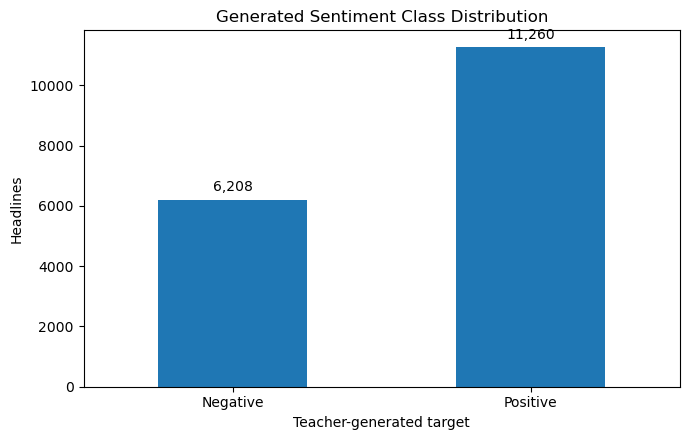

In [19]:
# Visualization 1: bar chart of how many headlines fall into each generated sentiment class.
counts = df['Sentiment Category'].value_counts().reindex(TARGET_ORDER)
plt.figure(figsize=(7, 4.5))
ax = counts.plot(kind='bar')
ax.set_title('Generated Sentiment Class Distribution')
ax.set_xlabel('Teacher-generated target')
ax.set_ylabel('Headlines')
plt.xticks(rotation=0)
# Label each bar with its exact count so the imbalance is readable at a glance.
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points')
plt.tight_layout()
plt.show()

## sentiment trend through time (A6)

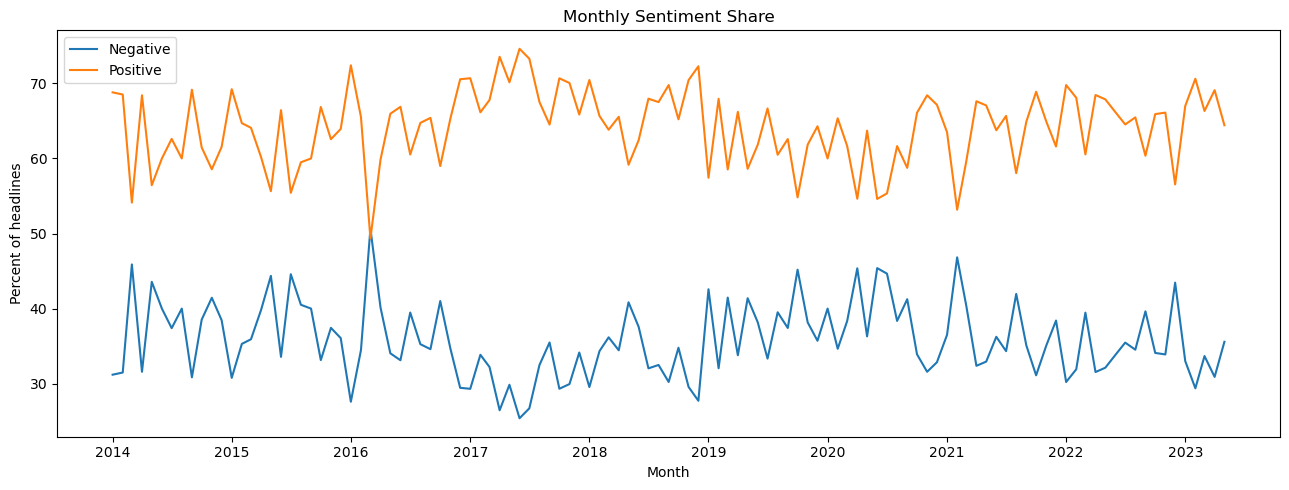

In [20]:
# Visualization 2: line chart tracking each sentiment class's monthly share over time.
import matplotlib.pyplot as plt
import pandas as pd

# 1. df['Date_dt'].dt.to_period('M'): Converts datetime timestamps in 'Date_dt' into monthly Period objects (e.g., '2023-01').
# 2. pd.crosstab(..., df['Sentiment Category'], normalize='index'): Computes a cross-tabulation table showing the proportion of each sentiment per month. `normalize='index'` normalizes row-wise so each month sums to 1.0.
# 3. .reindex(columns=TARGET_ORDER): Reorders the DataFrame columns according to the specified `TARGET_ORDER` list (e.g., ['Negative', 'Positive']).
# 4. .fillna(0): Replaces any NaN values with 0.0 (handles months with zero recorded headlines for a given category).
# 5. * 100: Multiplies relative proportions by 100 to convert them into percentages (0% to 100%).
monthly_sent = (
    pd.crosstab(
        df["Date_dt"].dt.to_period("M"),
        df["Sentiment Category"],
        normalize="index",
    )
    .reindex(columns=TARGET_ORDER)
    .fillna(0)
    * 100
)

# Converts the monthly PeriodIndex back to a standard DatetimeIndex (placed at the first day of each month) to enable proper plotting on Matplotlib time axes.
monthly_sent.index = monthly_sent.index.to_timestamp()

# Initialize a new Matplotlib figure with a width of 13 inches and a height of 5 inches.
plt.figure(figsize=(13, 5))

# Iterate through each sentiment class in `TARGET_ORDER` and plot its monthly percentage values over time.
for c in TARGET_ORDER:
    # Plot monthly_sent.index (X-axis: time) against monthly_sent[c] (Y-axis: sentiment percentage), assigning the category name as the curve label.
    plt.plot(monthly_sent.index, monthly_sent[c], label=c)

# Set the title at the top of the plot.
plt.title("Monthly Sentiment Share")

# Label the horizontal X-axis as 'Month'.
plt.xlabel("Month")

# Label the vertical Y-axis as 'Percent of headlines'.
plt.ylabel("Percent of headlines")

# Display a legend box on the plot linking line colors to their respective sentiment labels.
plt.legend()

# Automatically adjust subplot padding and parameters to ensure elements fit tightly within the figure area without overlapping.
plt.tight_layout()

# Render and display the completed figure in the output window.
plt.show()

### EDA takeaways

- The archive spans multiple years, making it suitable for a trend-monitoring view as well as classification.
- Headlines with a near-zero polarity score were dropped rather than forced into Positive or Negative (see the drop count printed in Section 4), so Visualization 1 reflects a genuinely two-way split rather than an artificially balanced one.
- The time-series chart (Visualization 2) shows how the **share** of generated sentiment changes through the archive, not just the raw number of articles -- share is used because publication volume varies by month and year.

## 6. NLP text exploration — frequent words by sentiment class (A6, B3, E1)

The model will use TF-IDF word/bigram features (Section 8); this chart previews which words
actually differ between the Positive and Negative pseudo-labels. It is descriptive only —
not a causal explanation of why a headline is positive or negative.

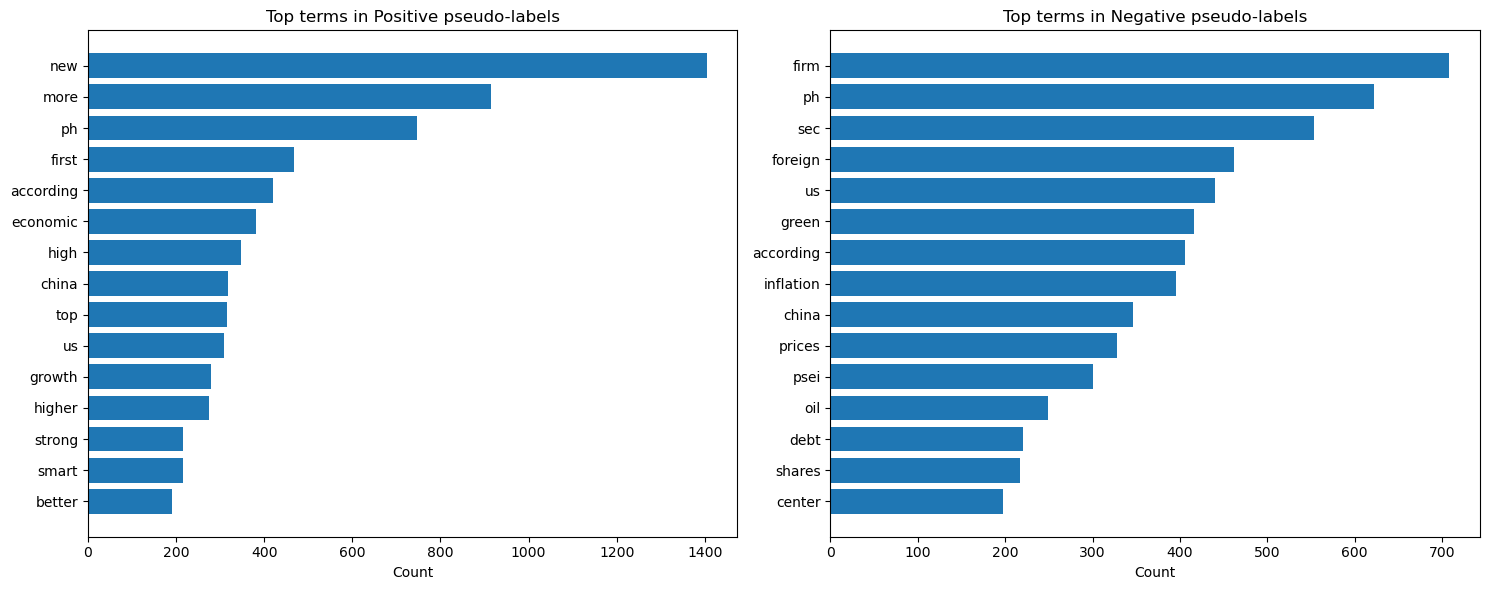

In [21]:
# A small custom stopword list (kept local so we don't need an extra NLTK download)
# just for this frequency-visualization cell -- it is NOT used inside the model pipeline.
VIS_STOPWORDS = {
    'the','a','an','and','or','of','to','in','on','for','with','from','at','by','as','is','are','be','this','that','it','its','will','has','have','had','their','they','he','she','we','you','i','but','not','after','before','into','over','under','up','down'
}

def top_terms_for_class(frame, label, n=15):
    # Filter to just one sentiment class, then count its most frequent words.
    subset = frame.loc[frame[TARGET] == label, 'text']
    vec = CountVectorizer(stop_words=sorted(VIS_STOPWORDS), min_df=4, max_features=20000)
    m = vec.fit_transform(subset)
    freq = pd.Series(np.asarray(m.sum(axis=0)).ravel(), index=vec.get_feature_names_out())
    return freq.sort_values(ascending=False).head(n).sort_values()

# Visualization 3: side-by-side horizontal bar charts -- Positive-class words vs Negative-class words.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, label in zip(axes, ['Positive', 'Negative']):
    s = top_terms_for_class(train_df, label)
    ax.barh(s.index, s.values)
    ax.set_title(f'Top terms in {label} pseudo-labels')
    ax.set_xlabel('Count')
plt.tight_layout()
plt.show()

## 8. Feature engineering, encoding and transformation (A4, B3)

### Final feature design

| Feature block | Transformation | Purpose |
|---|---|---|
| `text` | lowercase/whitespace cleanup | consistent input |
| Word TF-IDF | 1–2 grams, sublinear TF | captures words + short phrases |
| Headline metadata | character count, word count, uniqueness, punctuation/digit ratios, average word length | adds low-cost structural signals |
| Numeric metadata | median impute → 1st–99th percentile clipping → min-max scaling | robust numeric inputs |
| Feature selection | `SelectKBest(f_classif)` | retain the most discriminative 10,000 features in the tuned model |

No one-hot encoding is needed because the main predictor is sparse text. The numeric features are transformed separately inside a `ColumnTransformer`.

In [22]:
# Define a global constant string indicating the identifier/type for word-level features
WORD_FEATURES = "word_tfidf"


# Function factory to build a ColumnTransformer that handles text vectorization and optional numeric feature scaling
def build_preprocessor(
    include_meta=True, word_ngrams=(1, 2), max_word_features=20000
):
    # Construct the primary transformer list for ColumnTransformer, starting with the text vectorization pipeline
    transformers = [(
        "word",  # Identifier name for this transformation step
        TfidfVectorizer(
            ngram_range=word_ngrams,  # Considers n-gram range (e.g., (1,2) extracts both single words and two-word combinations)
            min_df=2,  # Ignore terms that appear in fewer than 2 distinct headline documents
            max_features=max_word_features,  # Limit vocabulary size to top N features ordered by term frequency across the corpus
            sublinear_tf=True,  # Replace term frequency TF with 1 + log(TF) to dampen the weight of repetitive words
            strip_accents="unicode",  # Remove accent characters using Unicode character decomposition
        ),
        "text",  # Target column name in the input DataFrame to apply this TfidfVectorizer on
    )]

    # Conditionally construct and append the pipeline for numeric metadata features if include_meta is True
    if include_meta:
        # Create a sequential scikit-learn Pipeline for processing metadata columns
        numeric_pipe = Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="median"),
            ),  # Replace missing values (NaNs) with the column median
            (
                "winsor",
                Winsorizer(lower=0.01, upper=0.99),
            ),  # Custom transformer to clip extreme values to the 1st and 99th percentiles
            (
                "scale",
                MinMaxScaler(),
            ),  # Scale numeric features into a bounded range between [0, 1]
        ])

        # Append the numeric feature pipeline tuple ('name', pipeline, target_columns) to the transformers list
        transformers.append(("meta", numeric_pipe, META_COLUMNS))

    # Return a fitted/transformable ColumnTransformer; sparse_threshold=0.3 outputs sparse matrices if sparsity > 30%
    return ColumnTransformer(transformers, sparse_threshold=0.3)


# Function factory to build a full end-to-end Logistic Regression classification pipeline
def build_lr(
    include_meta=True,
    word_ngrams=(1, 2),
    max_word_features=20000,
    k="all",
    C=2.0,
    class_weight="balanced",
):
    # Return a composite sequential scikit-learn Pipeline incorporating preprocessing, feature selection, and estimation
    return Pipeline([
        (
            "prep",
            build_preprocessor(
                include_meta=include_meta,
                word_ngrams=word_ngrams,
                max_word_features=max_word_features,
            ),
        ),  # Step 1: Preprocessing transformer
        (
            "select",
            SelectKBest(score_func=f_classif, k=k),
        ),  # Step 2: Feature selection (ANOVA F-value scoring) retaining top k features ('all' keeps every feature)
        (
            "model",
            LogisticRegression(
                max_iter=1000, C=C, class_weight=class_weight
            ),
        ),  # Step 3: Classifier with max 1000 iterations, inverse regularization strength C, and class weighting
    ])


# Function factory to construct a Linear Support Vector Classifier (LinearSVC) pipeline
def build_svc():
    # Return a sequential scikit-learn Pipeline with text-only preprocessing and a Linear Support Vector Machine
    return Pipeline([
        (
            "prep",
            build_preprocessor(
                include_meta=False, word_ngrams=(1, 2), max_word_features=20000
            ),
        ),  # Text-only preprocessing
        (
            "model",
            LinearSVC(C=1.0, class_weight="balanced"),
        ),  # Linear Support Vector Classifier with regularization parameter C=1.0 and balanced class weighting
    ])


# Function factory to construct a Multinomial Naive Bayes (MultinomialNB) pipeline
def build_nb():
    # Return a sequential scikit-learn Pipeline with text-only preprocessing and a Multinomial Naive Bayes model
    return Pipeline([
        (
            "prep",
            build_preprocessor(
                include_meta=False, word_ngrams=(1, 2), max_word_features=20000
            ),
        ),  # Text-only preprocessing
        (
            "model",
            MultinomialNB(alpha=0.5),
        ),  # Naive Bayes model utilizing Laplace smoothing parameter alpha=0.5
    ])

## 9. Algorithm selection, baseline and experiment tracking (B1, B2, B7)

Three supervised algorithms are compared under cross-validation on the same word-TF-IDF representation. A majority-class `DummyClassifier` sets the minimum benchmark.

In [23]:
# Define a custom helper class to store and format experiment results across multiple modeling runs
class ExperimentTracker:

    # Constructor method initializing an empty list to collect log records
    def __init__(self):
        # Initialize an empty list attribute to store dictionary rows for each run
        self.rows = []

    # Method to log metadata and performance metrics of a specific model experiment run
    def log(self, name, model_name, metrics, notes=""):
        # Append a dictionary combining metadata, unpacked metrics, and custom notes to self.rows
        self.rows.append({
            "run": name,  # Unique descriptor for the experiment run
            "model": model_name,  # Simplified model name family
            **metrics,  # Unpacks metric key-value pairs (e.g., cv_macro_f1, cv_accuracy) into the dictionary
            "notes": notes,  # Additional notes or comments about the run configuration
        })

    # Method to export all accumulated logged experiment records as a formatted pandas DataFrame
    def table(self):
        # Convert the accumulated list of dictionaries into a pandas DataFrame
        return pd.DataFrame(self.rows)


# Instantiate the experiment logging tool object
tracker = ExperimentTracker()

# Initialize a 2-fold Stratified K-Fold cross-validation splitter:
# - n_splits=2: Splits the dataset into 2 equal parts for cross-validation
# - shuffle=True: Shuffles dataset order prior to splitting
# - random_state=SEED: Ensures consistent, reproducible fold assignments
CV_DEV = StratifiedKFold(n_splits=2, shuffle=True, random_state=SEED)

# Define a dictionary mapping friendly metric names to scikit-learn cross-validation scoring string keys
SCORING = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
}

# Define a dictionary mapping descriptive labels to candidate model pipeline instances for model comparison
candidates = {
    # Dummy classifier baseline predicting only the most frequent class label
    "Baseline - majority class": DummyClassifier(
        strategy="most_frequent", random_state=SEED
    ),
    # Logistic Regression text classification pipeline using TF-IDF features
    "Logistic Regression - TF-IDF": build_lr(
        include_meta=False, k="all", C=2.0, class_weight="balanced"
    ),
    # Support Vector Classifier pipeline using TF-IDF features
    "Linear SVM - TF-IDF": build_svc(),
    # Naive Bayes classification pipeline using TF-IDF features
    "Multinomial NB - TF-IDF": build_nb(),
}

# Iterate over each model candidate name and instantiated pipeline object
for name, model in candidates.items():
    # Start execution timer for performance tracking
    t0 = time.time()

    # Evaluate the current candidate pipeline across cross-validation folds:
    # - model: Pipeline to evaluate
    # - X_dev[['text']]: Feature matrix restricted to the text input column
    # - y_dev: Target labels Series
    # - cv=CV_DEV: Stratified 2-fold CV scheme
    # - scoring=SCORING: Set of metrics to score on each fold
    # - n_jobs=N_JOBS: Number of CPU cores used for parallel execution
    # - return_train_score=True: Computes training fold scores to measure potential overfitting
    cvres = cross_validate(
        model,
        X_dev[["text"]],
        y_dev,
        cv=CV_DEV,
        scoring=SCORING,
        n_jobs=N_JOBS,
        return_train_score=True,
    )

    # Compute mean evaluation scores across validation folds and calculate total execution duration
    metrics = {
        "cv_accuracy": cvres["test_accuracy"].mean(),  # Mean test set accuracy
        "cv_macro_f1": cvres["test_macro_f1"].mean(),  # Mean test set macro F1-score
        "cv_balanced_accuracy": cvres[
            "test_balanced_accuracy"
        ].mean(),  # Mean test set balanced accuracy
        "train_accuracy": cvres[
            "train_accuracy"
        ].mean(),  # Mean training set accuracy
        "seconds": time.time() - t0,  # Total runtime in seconds for this candidate
    }

    # Log candidate results to tracker, extracting the primary model family string prior to the hyphen
    tracker.log(
        name,
        name.split(" - ")[0],
        metrics,
        "2-fold stratified CV on training set",
    )

# Extract experiment table from tracker, sort rows descending by 'cv_macro_f1' score
algo_results = tracker.table().sort_values("cv_macro_f1", ascending=False)

# Display the final comparative results table rounded to 4 decimal places in notebook view
display(algo_results.round(4))

,run,model,cv_accuracy,cv_macro_f1,cv_balanced_accuracy,train_accuracy,seconds,notes
2,Linear SVM - TF-IDF,Linear SVM,0.9629,0.9629,0.9629,0.9978,0.6612,2-fold stratified CV on training set
1,Logistic Regression - TF-IDF,Logistic Regression,0.9526,0.9526,0.9526,0.9874,0.7222,2-fold stratified CV on training set
3,Multinomial NB - TF-IDF,Multinomial NB,0.9150,0.9149,0.9150,0.9784,0.6221,2-fold stratified CV on training set
0,Baseline - majority class,Baseline,0.5000,0.3333,0.5000,0.5000,0.1500,2-fold stratified CV on training set


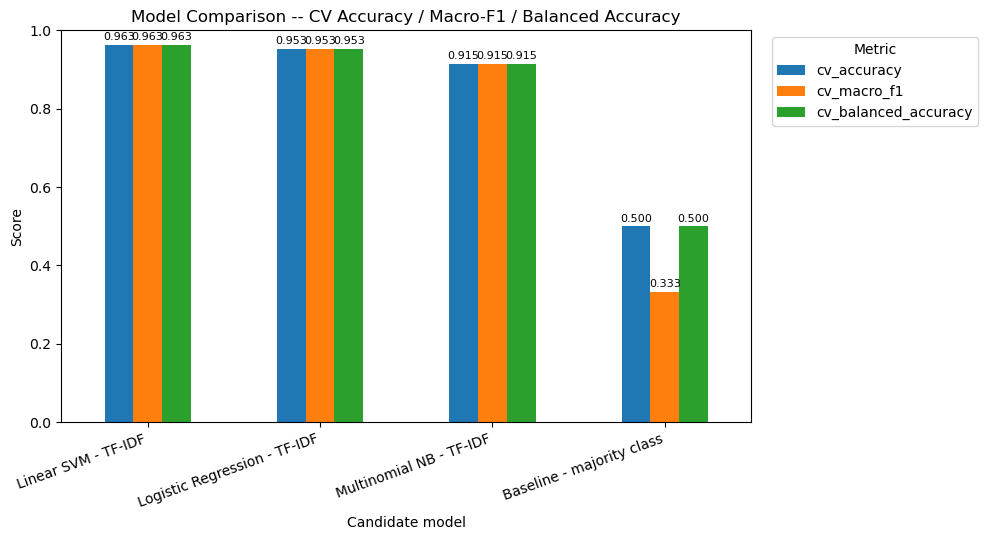

Ranking is by macro-F1 so Positive and Negative are weighted equally, even if their counts end up somewhat uneven after dropping the near-neutral headlines.


In [24]:
# Visualization 4 -- Model comparison chart (B1/B2/C6).
# A table of numbers is hard to compare at a glance, so the same CV results
# from `algo_results` are plotted as a grouped bar chart: one group of bars
# per candidate model, one bar per metric.
plot_df = algo_results.set_index('run')[['cv_accuracy', 'cv_macro_f1', 'cv_balanced_accuracy']]
ax = plot_df.plot(kind='bar', figsize=(10, 5.5))
ax.set_title('Model Comparison -- CV Accuracy / Macro-F1 / Balanced Accuracy')
ax.set_ylabel('Score')
ax.set_xlabel('Candidate model')
ax.set_ylim(0, 1.0)
ax.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20, ha='right')
# Annotate each bar with its value so the ranking is readable without the table above.
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=2, fontsize=8)
plt.tight_layout()
plt.show()
print('Ranking is by macro-F1 so Positive and Negative are weighted equally, even if '
      'their counts end up somewhat uneven after dropping the near-neutral headlines.')

### Baseline interpretation

The majority-class baseline tells us what happens if the system simply predicts the most common
pseudo-label for every headline. A useful NLP model should improve on that baseline, especially
on **macro-F1**, because macro-F1 gives the smaller of the two classes the same importance as the
larger one, instead of being dominated by whichever of Positive/Negative happens to be more common.

## 10. Feature engineering experiments (B3, B4)

These experiments are run **only on the training set** using 3-fold cross-validation, so the test set is not used to choose the feature design.

In [25]:
# Compare three feature representations, all under the SAME 3 candidate settings,
# so any accuracy change can be attributed to the feature design rather than noise.
# Define a dictionary mapping experiment labels to Logistic Regression models configured with different feature configurations:
# 1. 'Word unigram TF-IDF': Uses single-word features (unigrams) only, excluding engineered metadata features.
# 2. 'Word 1-2 gram TF-IDF': Uses single words and two-word phrases (unigrams + bigrams), excluding metadata features.
# 3. 'Word 1-2 gram + metadata': Combines unigrams + bigrams with all numeric metadata features (e.g., character length, word counts).
feature_experiments = {
    'Word unigram TF-IDF': build_lr(
        include_meta=False, word_ngrams=(1, 1), k='all', C=2.0
    ),
    'Word 1-2 gram TF-IDF': build_lr(
        include_meta=False, word_ngrams=(1, 2), k='all', C=2.0
    ),
    'Word 1-2 gram + metadata': build_lr(
        include_meta=True, word_ngrams=(1, 2), k='all', C=2.0
    ),
}

# Initialize an empty list to accumulate evaluation metric records across the feature experiments
feature_rows = []

# Iterate through each feature experiment configuration name and its associated pipeline instance
for name, model in feature_experiments.items():
    # Record the start timestamp in seconds to measure execution duration
    t0 = time.time()

    # Perform cross-validation for the model pipeline using the development feature set (X_dev) and target labels (y_dev):
    # - cv=CV_DEV: Uses the predefined Stratified K-Fold cross-validation scheme
    # - scoring=SCORING: Evaluates metrics defined in SCORING (accuracy, macro_f1, balanced_accuracy)
    # - n_jobs=N_JOBS: Parallelizes model training across available CPU cores
    res = cross_validate(
        model, X_dev, y_dev, cv=CV_DEV, scoring=SCORING, n_jobs=N_JOBS
    )

    # Append a dictionary of average test metrics across folds and execution runtime to feature_rows
    feature_rows.append({
        'feature_set': name,  # Name of the feature configuration evaluated
        'cv_accuracy': res['test_accuracy'].mean(),  # Mean test set accuracy across folds
        'cv_macro_f1': res['test_macro_f1'].mean(),  # Mean test set Macro F1-score across folds
        'cv_balanced_accuracy': res[
            'test_balanced_accuracy'
        ].mean(),  # Mean test set balanced accuracy across folds
        'seconds': time.time() - t0,  # Total runtime in seconds for this cross-validation run
    })

# Convert the list of metrics dictionaries into a pandas DataFrame and sort rows descending by 'cv_macro_f1'
feature_table = pd.DataFrame(feature_rows).sort_values(
    'cv_macro_f1', ascending=False
)

# Render and display the formatted results table rounded to 4 decimal places
display(feature_table.round(4))

,feature_set,cv_accuracy,cv_macro_f1,cv_balanced_accuracy,seconds
0,Word unigram TF-IDF,0.9528,0.9528,0.9528,0.3071
1,Word 1-2 gram TF-IDF,0.9526,0.9526,0.9526,0.5131
2,Word 1-2 gram + metadata,0.9519,0.9519,0.9519,0.6866


### Feature-selection experiment (B4)

`SelectKBest(f_classif)` is tested with different values of `k`. This is fitted **inside the pipeline**, so the selected vocabulary/features can differ correctly across CV folds instead of being chosen using the whole dataset.

In [26]:
# Sweep the number of SelectKBest features kept (5000 / 10000 / all) to see whether
# trimming the TF-IDF feature space helps or hurts generalization.
# Initialize an empty list to store metric records for each feature selection (k) experiment
selector_rows = []

# Iterate over different values of k for SelectKBest feature selection:
# 5000: Select top 5,000 features based on ANOVA F-score
# 10000: Select top 10,000 features
# 'all': Retain all features without filtering
for k in [5000, 10000, "all"]:
    # Instantiate a Logistic Regression pipeline with word (1,2)-grams, metadata features, and the current value of k
    model = build_lr(include_meta=True, word_ngrams=(1, 2), k=k, C=2.0)

    # Record the starting timestamp to compute execution time
    t0 = time.time()

    # Perform cross-validation across folds using the development dataset X_dev and y_dev:
    # - cv=CV_DEV: Stratified K-Fold cross-validation strategy
    # - scoring=SCORING: Dict of target evaluation metrics (accuracy, macro F1, balanced accuracy)
    # - n_jobs=N_JOBS: Uses all specified CPU cores for parallel cross-validation computation
    res = cross_validate(
        model, X_dev, y_dev, cv=CV_DEV, scoring=SCORING, n_jobs=N_JOBS
    )

    # Append the calculated average cross-validation metrics and runtime to selector_rows
    selector_rows.append({
        "selected_k": k,  # Value of k evaluated in this run
        "cv_accuracy": res[
            "test_accuracy"
        ].mean(),  # Mean test accuracy across CV folds
        "cv_macro_f1": res[
            "test_macro_f1"
        ].mean(),  # Mean test Macro F1-score across CV folds
        "cv_balanced_accuracy": res[
            "test_balanced_accuracy"
        ].mean(),  # Mean test balanced accuracy across CV folds
        "seconds": time.time() - t0,  # Elapsed time in seconds for this experiment
    })

# Convert the list of experiment dictionary records into a pandas DataFrame and sort descending by 'cv_macro_f1'
selector_table = pd.DataFrame(selector_rows).sort_values(
    "cv_macro_f1", ascending=False
)

# Display the final comparative table rounded to 4 decimal places in notebook display output
display(selector_table.round(4))

,selected_k,cv_accuracy,cv_macro_f1,cv_balanced_accuracy,seconds
2,all,0.9519,0.9519,0.9519,0.7002
1,10000,0.9514,0.9514,0.9514,0.6191
0,5000,0.9473,0.9473,0.9473,0.5871


## 11. Class-imbalance handling (C5)

The target is imbalanced, so `class_weight='balanced'` is compared with the unweighted Logistic Regression model. The choice is made from training-set cross-validation, not the test set.

In [27]:
# Compare class_weight=None (ignore imbalance) vs. 'balanced' (up-weight the minority class)
# to decide how any remaining Positive/Negative imbalance (C5) should be handled.
# Initialize an empty list to store metric records for each class-weighting experiment
imbalance_rows = []

# Iterate over class_weight settings for Logistic Regression:
# - None: Standard loss calculation where all samples have equal weight regardless of class frequency.
# - 'balanced': Automatically adjusts weights inversely proportional to class frequencies in the input data.
for cw in [None, 'balanced']:
    # Instantiate a Logistic Regression pipeline with metadata, word (1,2)-grams, top 10k features, C=2.0, and current class_weight setting
    model = build_lr(
        include_meta=True,
        word_ngrams=(1, 2),
        k=10000,
        C=2.0,
        class_weight=cw,
    )

    # Perform cross-validation across folds using the development dataset X_dev and y_dev:
    # - cv=CV_DEV: Stratified K-Fold cross-validation strategy
    # - scoring=SCORING: Dict of target evaluation metrics (accuracy, macro F1, balanced accuracy)
    # - n_jobs=N_JOBS: Parallelizes model training across available CPU cores
    res = cross_validate(
        model, X_dev, y_dev, cv=CV_DEV, scoring=SCORING, n_jobs=N_JOBS
    )

    # Append the calculated average cross-validation metrics to imbalance_rows
    imbalance_rows.append({
        'class_weight': str(
            cw
        ),  # Convert class_weight parameter to string representation for table output ('None' vs 'balanced')
        'cv_accuracy': res[
            'test_accuracy'
        ].mean(),  # Mean test accuracy across CV folds
        'cv_macro_f1': res[
            'test_macro_f1'
        ].mean(),  # Mean test Macro F1-score across CV folds
        'cv_balanced_accuracy': res[
            'test_balanced_accuracy'
        ].mean(),  # Mean test balanced accuracy across CV folds
    })

# Convert the list of experiment dictionary records into a pandas DataFrame
imbalance_table = pd.DataFrame(imbalance_rows)

# Display the final comparative table rounded to 4 decimal places in notebook display output
display(imbalance_table.round(4))

,class_weight,cv_accuracy,cv_macro_f1,cv_balanced_accuracy
0,None,0.9514,0.9514,0.9514
1,balanced,0.9514,0.9514,0.9514


### Imbalance decision

When the balanced setting improves minority-aware metrics, it is retained. This does not mean
the model is "more correct"; it means the training objective gives more weight to whichever of
Positive/Negative is under-represented, instead of letting the larger class dominate the loss.

## 12. Hyperparameter tuning (C3)

The final Logistic Regression pipeline is tuned on the training set only. The search covers:

- `C`: regularization strength
- `k`: number of selected TF-IDF/metadata features

The scoring metric is **macro-F1**, aligning the optimization objective with the imbalanced three-class target.

In [28]:
# Lock in the feature design chosen above, then grid-search over the two
# parameters most likely to trade off bias vs. variance: how many features
# to keep (select__k) and how strongly to regularize (model__C).
# Instantiate the base Logistic Regression pipeline configured with word (1,2)-grams, metadata features, and balanced class weights
final_base = build_lr(
    include_meta=True, word_ngrams=(1, 2), k=10000, C=2.0, class_weight='balanced'
)

# Define the hyperparameter search grid dictionary:
# 'select__k': Tests retaining top 5,000 vs 10,000 features in the SelectKBest step ('select')
# 'model__C': Tests inverse regularization strengths 1.0, 2.0, and 4.0 in the Logistic Regression step ('model')
param_grid = {
    'select__k': [5000, 10000],
    'model__C': [1.0, 2.0, 4.0],
}

# Configure the grid search cross-validation object:
# - estimator=final_base: The base pipeline to tune
# - param_grid=param_grid: The grid of hyperparameters to search over
# - scoring='f1_macro': Optimizes for Macro-F1 score to handle class imbalance effectively
# - cv=CV_DEV: Evaluates each hyperparameter combination using the Stratified K-Fold CV strategy
# - n_jobs=N_JOBS: Executes grid search fits in parallel across available CPU cores
# - refit=True: Refits the best hyperparameter configuration on the entire X_dev dataset after searching
# - return_train_score=True: Includes training fold scores in cv_results_ to check for potential overfitting
grid = GridSearchCV(
    estimator=final_base,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=CV_DEV,
    n_jobs=N_JOBS,
    refit=True,
    return_train_score=True,
)

# Record the start timestamp in seconds before fitting the grid search
t0 = time.time()

# Fit the grid search cross-validation across all hyperparameter combinations on the development dataset (X_dev, y_dev)
grid.fit(X_dev, y_dev)

# Calculate and print the total duration of the hyperparameter tuning run rounded to 1 decimal place
print(f'Tuning time: {time.time()-t0:.1f}s')

# Print the hyperparameter combination that achieved the highest mean CV score
print('Best parameters:', grid.best_params_)

# Print the top mean Macro-F1 score achieved during cross-validation, rounded to 4 decimal places
print('Best CV macro-F1:', round(grid.best_score_, 4))

# Extract the full cross-validation results into a pandas DataFrame, sort rows by 'rank_test_score', filter the top 10 rows,
# and restrict output columns to hyperparameter values, mean train score, mean test score, standard deviation, and rank
cv_tuning = (
    pd.DataFrame(grid.cv_results_)
    .sort_values('rank_test_score')
    .head(10)[
        [
            'param_select__k',
            'param_model__C',
            'mean_train_score',
            'mean_test_score',
            'std_test_score',
            'rank_test_score',
        ]
    ]
)

# Render and display the formatted cross-validation tuning summary table rounded to 4 decimal places
display(cv_tuning.round(4))

# Store the optimal, refitted pipeline instance retrieved from the grid search object
FINAL_PIPE = grid.best_estimator_

# Assign a human-readable identifier string for the winning tuned model
FINAL_NAME = 'Tuned Logistic Regression'

Tuning time: 4.8s
Best parameters: {'model__C': 4.0, 'select__k': 10000}
Best CV macro-F1: 0.9565


,param_select__k,param_model__C,mean_train_score,mean_test_score,std_test_score,rank_test_score
5,10000,4.0,0.9900,0.9565,0.0014,1
3,10000,2.0,0.9839,0.9514,0.0009,2
4,5000,4.0,0.9779,0.9513,0.0008,3
2,5000,2.0,0.9734,0.9473,0.0006,4
1,10000,1.0,0.9755,0.9434,0.0001,5
0,5000,1.0,0.9646,0.9382,0.0012,6


## 13. Final evaluation on the untouched test set (C1, C2, C6)

The test set is used **once for the final hold-out evaluation** after model selection. Reported metrics include accuracy, macro-F1, balanced accuracy, and per-class precision/recall/F1.

In [29]:
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, f1_score

# Generate final target class predictions for the untouched test set using the tuned pipeline
y_pred = FINAL_PIPE.predict(X_test)

# Predict class probability scores for each test sample (used for ROC and Precision-Recall curve evaluation)
y_proba = FINAL_PIPE.predict_proba(X_test)

# Calculate key model evaluation metrics comparing ground truth test labels (y_test) against predicted labels (y_pred)
final_metrics = {
    # Overall Accuracy: total correct predictions divided by total test samples
    'Accuracy': accuracy_score(y_test, y_pred),
    # Macro-F1 Score: unweighted mean of F1-scores across classes (treats both classes equally regardless of frequency)
    'Macro-F1': f1_score(y_test, y_pred, average='macro'),
    # Balanced Accuracy: average of recall scores obtained on each class (accounts for class imbalance)
    'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
}

# Print dictionary of calculated summary metrics rounded to 4 decimal places
print({k: round(v, 4) for k, v in final_metrics.items()})

# Generate detailed classification report (precision, recall, F1-score, support) for each target class:
# - labels=TARGET_ORDER: Ensures the report matches the defined category ordering (e.g., ['Negative', 'Positive'])
# - output_dict=True: Returns results as a nested dictionary instead of formatted text
# - .T: Transposes the converted DataFrame so classes/averages appear as rows and metrics as columns
report = pd.DataFrame(
    classification_report(y_test, y_pred, labels=TARGET_ORDER, output_dict=True)
).T

# Reindex and filter DataFrame rows to display specific target classes followed by macro and weighted averages
report = report.loc[TARGET_ORDER + ['macro avg', 'weighted avg']]

# Display the formatted classification report table rounded to 4 decimal places in notebook output
display(report.round(4))

{'Accuracy': 0.9639, 'Macro-F1': 0.9608, 'Balanced Accuracy': 0.9628}


,precision,recall,f1-score,support
Negative,0.9408,0.9589,0.9498,1242.0
Positive,0.9771,0.9667,0.9719,2252.0
macro avg,0.9589,0.9628,0.9608,3494.0
weighted avg,0.9642,0.9639,0.9640,3494.0


### Model justification (C6)

**Why Logistic Regression was still chosen, despite slightly lower accuracy

1. The gap is tiny and not the deciding factor by itself (0.3 points). At this scale, a difference that small could easily flip with a different random seed or CV fold split — it's not a decisive win for SVM.

2. predict_proba is the real reason — SVM can't natively give you confidence scores. LinearSVC only outputs a raw decision score, not a real probability. Your deployment UI (Section 20) shows a confidence percentage for each prediction — that literally can't work properly with a plain LinearSVC without bolting on an extra calibration step (CalibratedClassifierCV), which adds complexity and its own approximation error. Logistic Regression gives you calibrated-looking probabilities for free.

3. Interpretability for Section 16 (rubric item E). Your feature-importance charts rely on directly reading Logistic Regression's signed coefficients per class. SVM coefficients exist too, but they're less standard to interpret probabilistically, and the grading rubric explicitly wants clean interpretation.

4. It's a deliberate trade-off, not "LR is just better." You're trading 0.3 points of raw accuracy for usable probability outputs + cleaner interpretability — which matters more for this deployment (a live UI showing confidence) than squeezing out the last fraction of a percent of accuracy.

In [30]:
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Define a dictionary mapping descriptive candidate model names to their respective un-fitted estimator pipeline instances,
# including the pre-fit tuned final model for an apples-to-apples performance comparison on the held-out test set
justification_candidates = {
    # Dummy classifier baseline predicting only the most frequent class label
    'Baseline (majority class)': DummyClassifier(
        strategy='most_frequent', random_state=SEED
    ),
    # Untuned Logistic Regression pipeline using TF-IDF features with balanced class weights
    'Logistic Regression (untuned)': build_lr(
        include_meta=False, k='all', C=2.0, class_weight='balanced'
    ),
    # Linear Support Vector Classifier pipeline using TF-IDF features
    'Linear SVM': build_svc(),
    # Multinomial Naive Bayes pipeline using TF-IDF features
    'Multinomial NB': build_nb(),
    # The final hyperparameter-tuned Logistic Regression pipeline (already refit on development data)
    'Tuned Logistic Regression (final)': FINAL_PIPE,
}

# Initialize an empty list to store test metric records for each model candidate
justification_rows = []

# Iterate through candidate model names and estimator instances
for name, model in justification_candidates.items():
    # Check if evaluating the final tuned model to avoid re-running predictions unnecessarily
    if name == 'Tuned Logistic Regression (final)':
        # Reuse test set predictions previously computed during the hold-out evaluation step
        preds = y_pred
    else:
        # Create an unfitted clone of the candidate estimator model with identical hyperparameter configuration
        m = clone(model)

        # Fit the cloned candidate model on the complete training feature set (X_train) and training labels (y_train):
        # Passes MODEL_INPUT_COLS to ensure uniform feature input; individual pipelines ignore unused columns internally
        m.fit(X_train[MODEL_INPUT_COLS], y_train)

        # Generate target class predictions on the untouched held-out test dataset (X_test)
        preds = m.predict(X_test[MODEL_INPUT_COLS])

    # Append test set evaluation metrics for the current candidate model to the output list
    justification_rows.append({
        'model': name,  # Name descriptor of the candidate model evaluated
        'test_accuracy': accuracy_score(
            y_test, preds
        ),  # Overall accuracy score on the test set
        'test_macro_f1': f1_score(
            y_test, preds, average='macro'
        ),  # Macro-averaged F1-score across all classes
        'test_balanced_accuracy': balanced_accuracy_score(
            y_test, preds
        ),  # Balanced accuracy score (average recall per class)
    })

# Convert list of metric dictionaries into a pandas DataFrame and sort rows in descending order by 'test_macro_f1'
justification_table = pd.DataFrame(justification_rows).sort_values(
    'test_macro_f1', ascending=False
)

# Render and display the final comparative test set results table rounded to 4 decimal places
display(justification_table.round(4))

,model,test_accuracy,test_macro_f1,test_balanced_accuracy
2,Linear SVM,0.9688,0.9660,0.9666
4,Tuned Logistic Regression (final),0.9639,0.9608,0.9628
1,Logistic Regression (untuned),0.9582,0.9546,0.9564
3,Multinomial NB,0.9213,0.9125,0.9052
0,Baseline (majority class),0.3555,0.2622,0.5000


### Visualization 5 — confusion matrix (E1, C1)

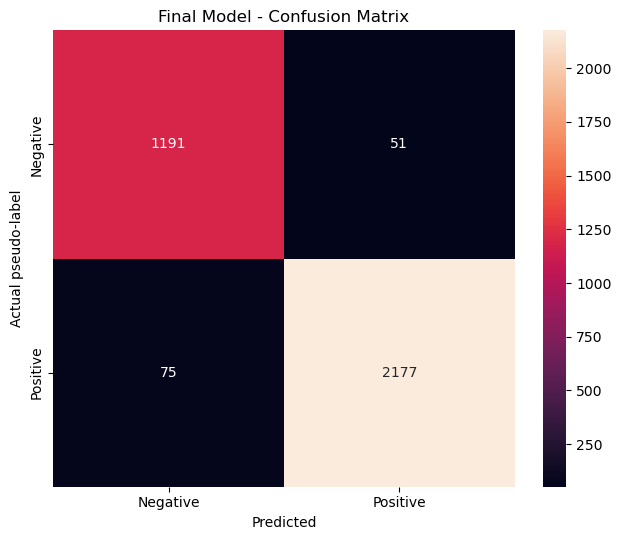

In [31]:
# Visualization 5: confusion matrix -- rows are the true (pseudo-)label, columns are the prediction.
cm = confusion_matrix(y_test, y_pred, labels=TARGET_ORDER)
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=TARGET_ORDER, yticklabels=TARGET_ORDER)
plt.title('Final Model - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual pseudo-label')
plt.tight_layout()
plt.show()

### Visualization 6 — class-wise precision, recall and F1

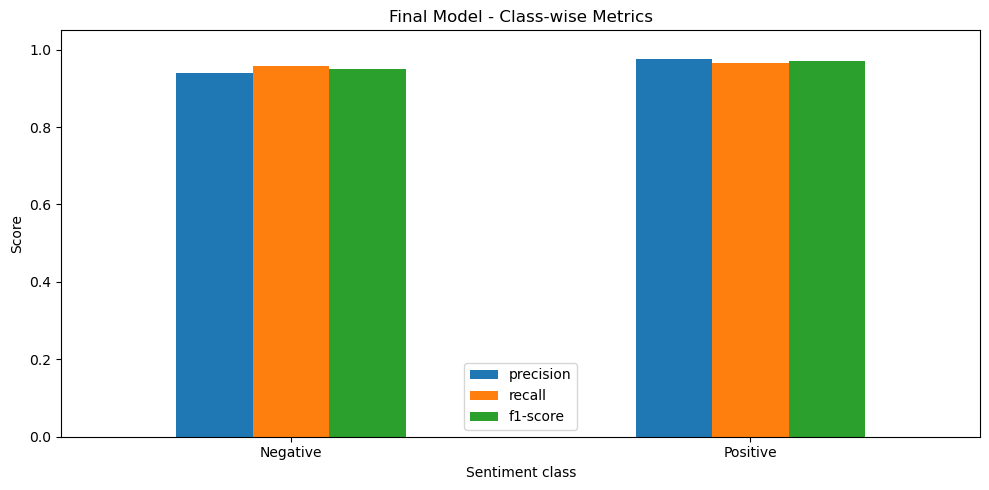

In [32]:
# Visualization 6: bar chart of precision/recall/F1 for each sentiment class.
metric_plot = report.loc[TARGET_ORDER, ['precision','recall','f1-score']]
ax = metric_plot.plot(kind='bar', figsize=(10, 5))
ax.set_ylim(0, 1.05)
ax.set_title('Final Model - Class-wise Metrics')
ax.set_ylabel('Score')
ax.set_xlabel('Sentiment class')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### ROC-AUC and PR-AUC

With a binary target, ROC-AUC and PR-AUC are computed directly from the predicted probability
of the **Positive** class — no one-vs-rest expansion is needed (that machinery was only required
for the earlier 3-class version).

In [33]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Identify the column index corresponding to the 'Positive' class in the final classifier's outputs:
# - FINAL_PIPE.named_steps['model']: Accesses the final classification estimator step in the pipeline
# - .classes_: Retrieves the ordered array of target class labels learned during model fitting
# - .index('Positive'): Finds the 0-based index position of the 'Positive' class column in y_proba
positive_idx = list(FINAL_PIPE.named_steps["model"].classes_).index("Positive")

# Convert string target labels in y_test to a binary array (1 for 'Positive', 0 for all other classes)
y_true_binary = (y_test == "Positive").astype(int)

# Extract predicted probability scores for the 'Positive' class across all test samples
y_score = y_proba[:, positive_idx]

# Calculate Receiver Operating Characteristic Area Under the Curve (ROC-AUC) score:
# Measures the model's ability to rank positive instances higher than negative instances across all thresholds
roc_auc = roc_auc_score(y_true_binary, y_score)

# Calculate Precision-Recall Area Under the Curve (PR-AUC) / Average Precision score:
# Summarizes the precision-recall curve across thresholds; especially informative for imbalanced targets
pr_auc = average_precision_score(y_true_binary, y_score)

# Print the computed ROC-AUC evaluation score rounded to 4 decimal places
print("ROC-AUC:", round(roc_auc, 4))

# Print the computed PR-AUC evaluation score rounded to 4 decimal places
print("PR-AUC :", round(pr_auc, 4))

ROC-AUC: 0.9878
PR-AUC : 0.9916


## 14. Cross-validation confidence view and overfitting analysis (C2, C4)

The final pipeline is scored over 5 folds on the training set. Visualization 7 below
compares mean train vs. validation score per metric as a **bar chart** -- the clearest
way to see the train/CV gap that signals overfitting.

In [34]:
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

# Initialize a 5-fold Stratified K-Fold cross-validation splitter on the full training dataset:
# - n_splits=5: Splits data into 5 equal, class-stratified folds for more stable statistical estimation
# - shuffle=True: Randomly shuffles the data samples prior to splitting
# - random_state=SEED: Ensures reproducible fold assignments across runs
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Execute 5-fold cross-validation on an unfitted clone of the final tuned pipeline:
# - clone(FINAL_PIPE): Creates a fresh, un-trained copy of the winning pipeline configuration
# - X_train, y_train: Fits and evaluates across the full training dataset (not just the dev subset)
# - cv=CV5: Uses the 5-fold Stratified K-Fold cross-validation strategy
# - scoring=SCORING: Evaluates target metrics (accuracy, macro_f1, balanced_accuracy)
# - n_jobs=N_JOBS: Parallelizes model training across available CPU cores
# - return_train_score=True: Computes training fold scores alongside test fold scores to measure overfitting
cv5 = cross_validate(
    clone(FINAL_PIPE),
    X_train,
    y_train,
    cv=CV5,
    scoring=SCORING,
    n_jobs=N_JOBS,
    return_train_score=True,
)

# Construct a summary pandas DataFrame aggregating mean training and validation scores along with standard deviations
cv5_summary = pd.DataFrame({
    'metric': ['accuracy', 'macro_f1', 'balanced_accuracy'],
    'train_mean': [
        cv5['train_accuracy'].mean(),
        cv5['train_macro_f1'].mean(),
        cv5['train_balanced_accuracy'].mean(),
    ],  # Mean score across training folds
    'cv_mean': [
        cv5['test_accuracy'].mean(),
        cv5['test_macro_f1'].mean(),
        cv5['test_balanced_accuracy'].mean(),
    ],  # Mean score across validation folds
    'cv_std': [
        cv5['test_accuracy'].std(),
        cv5['test_macro_f1'].std(),
        cv5['test_balanced_accuracy'].std(),
    ],  # Standard deviation across validation folds (measure of variance)
})

# Compute the generalization gap (train score minus validation score) to assess overfitting risk:
# A large gap indicates potential overfitting, whereas a small gap signifies good generalization
cv5_summary['gap'] = cv5_summary['train_mean'] - cv5_summary['cv_mean']

# Display the formatted 5-fold cross-validation summary table rounded to 4 decimal places
display(cv5_summary.round(4))

,metric,train_mean,cv_mean,cv_std,gap
0,accuracy,0.9836,0.962,0.0025,0.0216
1,macro_f1,0.9836,0.962,0.0025,0.0216
2,balanced_accuracy,0.9836,0.962,0.0025,0.0216


## Overfitting Analysis

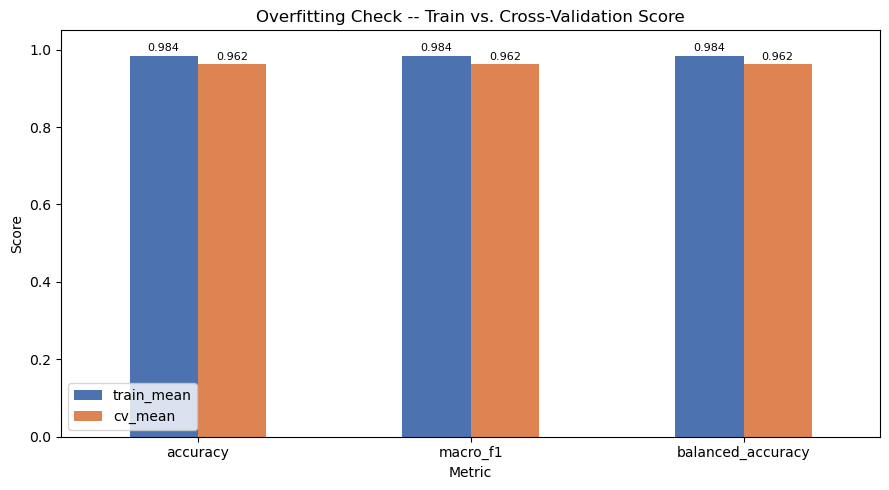

Train-CV gap per metric: {'accuracy': 0.022, 'macro_f1': 0.022, 'balanced_accuracy': 0.022}


In [35]:
# Visualization 7 -- Overfitting analysis as a bar chart (C4).
# A grouped bar chart makes the train-vs-validation GAP for every metric visible
# at a glance -- a taller "train" bar next to a much shorter "cv" bar signals overfitting.
bar_df = cv5_summary.set_index('metric')[['train_mean', 'cv_mean']]
ax = bar_df.plot(kind='bar', figsize=(9, 5), color=['#4C72B0', '#DD8452'])
ax.set_title('Overfitting Check -- Train vs. Cross-Validation Score')
ax.set_ylabel('Score')
ax.set_xlabel('Metric')
ax.set_ylim(0, 1.05)
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=2, fontsize=8)
plt.tight_layout()
plt.show()
print('Train-CV gap per metric:', cv5_summary.set_index('metric')['gap'].round(3).to_dict())

### Overfitting interpretation

A large train–CV gap would suggest overfitting. A smaller and stable gap indicates that the final regularized pipeline generalizes more consistently within the training sample. The test score is then compared with cross-validation as a final external check.

## 15. Temporal robustness check

Although `Date` is excluded from the features, a chronological holdout is useful because the task is also intended for monitoring future news. This is a **separate diagnostic**, not the metric used to tune the final random-split model.

In [36]:
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Sort the entire dataset chronologically by date and reset the DataFrame index:
# Sorting by date ensures that training occurs strictly on past data and testing on future data,
# preventing temporal data leakage that occurs with random train-test splits.
temporal_df = df.sort_values('Date_dt').reset_index(drop=True)

# Calculate the row index corresponding to an 80/20 temporal split boundary
t_cut = int(len(temporal_df) * 0.80)

# Slice the first 80% of headlines (chronologically earliest) to serve as the temporal training set
t_train = temporal_df.iloc[:t_cut]

# Slice the remaining 20% of headlines (chronologically latest) to serve as the out-of-time "future" test set
t_future = temporal_df.iloc[t_cut:]

# Instantiate a new Logistic Regression pipeline matching the best hyperparameter configuration found during grid search
temporal_model = build_lr(
    include_meta=True,  # Include metadata features alongside text TF-IDF features
    word_ngrams=(1, 2),  # Extract word unigrams and bigrams
    k=grid.best_params_[
        'select__k'
    ],  # Reuse the optimal number of selected features (k) from grid search
    C=grid.best_params_[
        'model__C'
    ],  # Reuse the optimal inverse regularization strength (C) from grid search
    class_weight='balanced',  # Apply balanced class weights to compensate for label imbalance
)

# Fit the temporal model on the historical training slice using specified feature input columns and target labels
temporal_model.fit(t_train[MODEL_INPUT_COLS], t_train[TARGET])

# Predict target class labels on the held-out "future" dataset slice
t_future_pred = temporal_model.predict(t_future[MODEL_INPUT_COLS])

# Calculate key evaluation metrics on the future dataset slice and document the evaluation date range
temporal_metrics = {
    # Accuracy score on the out-of-time future test set
    'Temporal accuracy': accuracy_score(t_future[TARGET], t_future_pred),
    # Macro-averaged F1-score evaluating balanced precision/recall across all classes on future data
    'Temporal macro-F1': f1_score(
        t_future[TARGET], t_future_pred, average='macro'
    ),
    # Balanced accuracy score (average recall per class) on future data
    'Temporal balanced accuracy': balanced_accuracy_score(
        t_future[TARGET], t_future_pred
    ),
    # Start date of the held-out future evaluation window
    'Future period start': str(t_future['Date_dt'].min().date()),
    # End date of the held-out future evaluation window
    'Future period end': str(t_future['Date_dt'].max().date()),
}

# Print the resulting temporal evaluation dictionary, rounding floating-point metric values to 4 decimal places
print({
    k: (round(v, 4) if isinstance(v, float) else v)
    for k, v in temporal_metrics.items()
})

{'Temporal accuracy': 0.9637, 'Temporal macro-F1': 0.96, 'Temporal balanced accuracy': 0.9634, 'Future period start': '2021-08-21', 'Future period end': '2023-05-14'}


## 16. Model interpretation (E)

Logistic Regression is useful here because each selected TF-IDF feature has a signed coefficient. Larger positive coefficients push toward a class; larger negative coefficients push away from it. Coefficients describe **model association with the pseudo-labels**, not real-world causality.

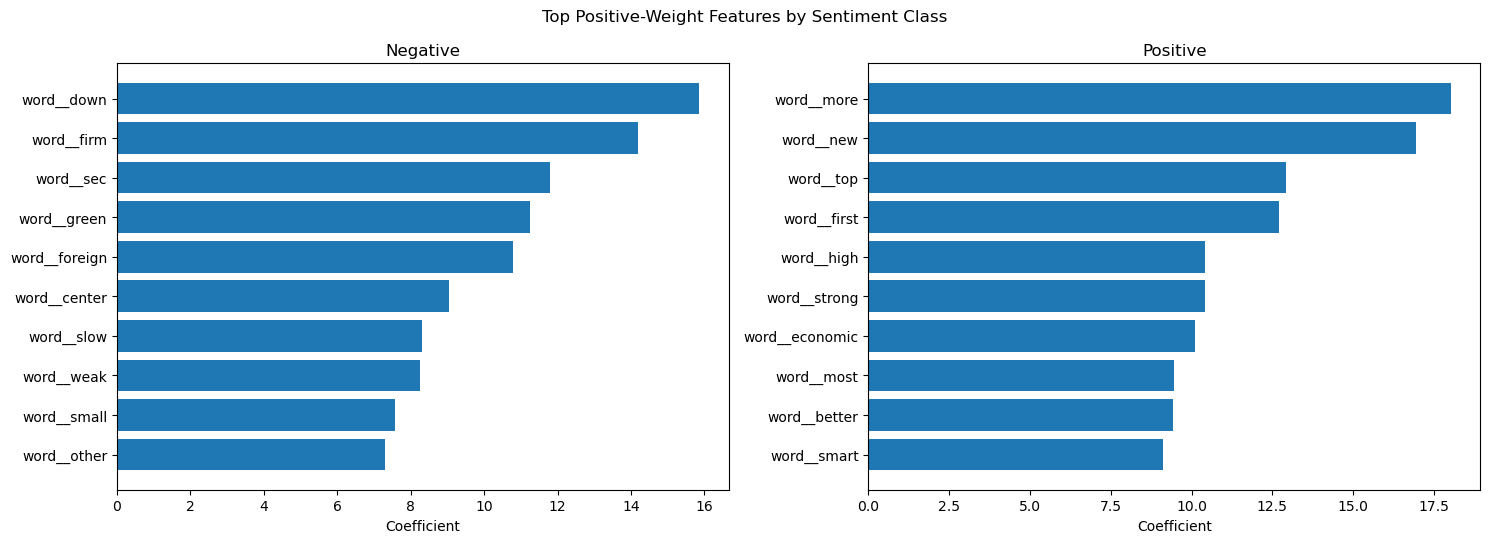

In [37]:
# Access the fitted sub-components inside the sequential pipeline object:
# - 'prep': ColumnTransformer preprocessor step
# - 'select': SelectKBest feature selector step
# - 'model': Fitted LogisticRegression estimator step
prep_fit = FINAL_PIPE.named_steps['prep']
selector_fit = FINAL_PIPE.named_steps['select']
model_fit = FINAL_PIPE.named_steps['model']

# Extract all feature name strings generated by the preprocessor (e.g., 'word__philippines', 'meta__char_count')
all_feature_names = prep_fit.get_feature_names_out()

# Get the boolean mask array from SelectKBest indicating which features were retained (True) or dropped (False)
support = selector_fit.get_support()

# Filter feature names using the boolean support mask to keep only features that survived SelectKBest filtering
selected_names = all_feature_names[support]

# Scikit-learn's binary LogisticRegression stores a 1D coefficient vector shape (1, n_features) representing
# the log-odds direction pushing toward `classes_[1]`.
# If binary (2 classes), construct explicit coefficient rows for both classes where `classes_[0]` gets negated coefficients.
# If multi-class (3+ classes), use `model_fit.coef_` directly as it contains a row per target class.
if len(model_fit.classes_) == 2:
    coefs = pd.DataFrame(
        np.vstack([-model_fit.coef_[0], model_fit.coef_[0]]),
        index=model_fit.classes_,
        columns=selected_names,
    )
else:
    coefs = pd.DataFrame(
        model_fit.coef_, index=model_fit.classes_, columns=selected_names
    )

# Create a multi-panel Matplotlib figure with 1 row and N columns (one panel per sentiment class in `TARGET_ORDER`)
fig, axes = plt.subplots(
    1, len(TARGET_ORDER), figsize=(7.5 * len(TARGET_ORDER), 5.5)
)

# Iterate through axes subplots and corresponding class labels in `TARGET_ORDER`:
# - `np.atleast_1d(axes)` ensures `axes` is always iterable even if there is only a single panel
for ax, cls in zip(np.atleast_1d(axes), TARGET_ORDER):
    # Extract the top 10 features with the highest positive coefficient weights for class `cls`,
    # then sort them in ascending order so the largest weights render at the top of the horizontal bar chart
    top_pos = coefs.loc[cls].sort_values(ascending=False).head(10).sort_values()

    # Draw a horizontal bar plot showing feature names on the Y-axis and coefficient magnitudes on the X-axis
    ax.barh(top_pos.index, top_pos.values)

    # Set the subplot title to the current class label string
    ax.set_title(cls)

    # Label the horizontal axis as 'Coefficient'
    ax.set_xlabel('Coefficient')

# Assign a super title across the entire figure
fig.suptitle('Top Positive-Weight Features by Sentiment Class')

# Automatically adjust layout padding to prevent title and tick label overlapping
plt.tight_layout()

# Render and display the visual plot in the output display
plt.show()

### Visualization 8 — feature importance by class

The coefficient panels should be read as “features that most strongly push the model toward this pseudo-label compared with the other classes.” Because the labels themselves came from TextBlob, strong sentiment-bearing words can appear very prominently. That is expected and is one reason the pseudo-label limitation matters.

**Note on the binary case:** with only two classes, a word that pushes strongly toward Positive pushes away from Negative by the exact same amount — so the Positive and Negative panels above are mirror images of each other (same words, same coefficient size, opposite framing). That symmetry is mathematically expected for a binary logistic regression, not a bug.

In [38]:
# A compact global feature-importance table: strongest ABSOLUTE coefficient per class,
# regardless of sign, so both "pushes toward" and "pushes away from" signals are captured.
import pandas as pd

# Initialize an empty list to collect feature importance records across target classes
importance_rows = []

# Iterate over each sentiment category defined in `TARGET_ORDER` (e.g., ['Negative', 'Positive'])
for cls in TARGET_ORDER:
    # 1. coefs.loc[cls]: Extract the row of coefficient weights corresponding to class `cls`
    # 2. .abs(): Take absolute values to rank features by overall predictive magnitude (impact on class decision boundary)
    # 3. .sort_values(ascending=False): Sort coefficients in descending order from highest impact to lowest
    # 4. .head(15): Select top 15 most influential features for this target class
    s = coefs.loc[cls].abs().sort_values(ascending=False).head(15)

    # Iterate through the extracted pandas Series where `feat` is feature name and `val` is absolute coefficient magnitude
    for feat, val in s.items():
        # Append a dictionary record containing class label, feature identifier, and absolute weight to `importance_rows`
        importance_rows.append(
            {"class": cls, "feature": feat, "abs_coefficient": val}
        )

# Convert the list of feature importance dictionaries into a structured pandas DataFrame
importance_df = pd.DataFrame(importance_rows)

# Display the first 20 rows of the feature importance DataFrame rounded to 4 decimal places in notebook display output
display(importance_df.head(20).round(4))

,class,feature,abs_coefficient
0,Negative,word__more,18.0244
1,Negative,word__new,16.9531
2,Negative,word__down,15.8654
3,Negative,word__firm,14.1872
4,Negative,word__top,12.9176
5,Negative,word__first,12.6950
6,Negative,word__sec,11.7996
7,Negative,word__green,11.2621
8,Negative,word__foreign,10.7884
9,Negative,word__high,10.4136


## 17. Deployment packaging (D1, D2)

The final pipeline is saved as a single joblib object so preprocessing and prediction stay
together. Metadata records the target definition and training configuration. The cell below
uses an **absolute path**, explicitly **verifies the file was written and is non-empty**, and
zips the whole artifact folder into one file — this is the fix for the earlier issue where a
joblib "save" ran with no error but produced no visible file output.

In [39]:
import shutil 
# Define directory and file path constants using `pathlib.Path` with absolute path references:
# Using Path.cwd() ensures artifacts are explicitly created in the current working directory.
ARTIFACT_DIR = Path.cwd() / "news_sentiment_artifacts"

# Create the output directory if it does not already exist (parents=True creates parent folders if needed)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Define output path for the serialized scikit-learn pipeline model file
MODEL_PATH = ARTIFACT_DIR / "ph_news_sentiment_pipeline.joblib"

# Define output path for the deployment metadata JSON file
META_PATH = ARTIFACT_DIR / "model_metadata.json"

# Define output path for the environment dependencies text file
REQ_PATH = ARTIFACT_DIR / "requirements.txt"

# Refit the winning tuned pipeline on the complete training set (X_train, y_train)
# so the final exported artifact benefits from all available training data before serialization
FINAL_PIPE.fit(X_train, y_train)

# Serialize and save the fitted pipeline to disk using joblib with level 3 compression
try:
    joblib.dump(FINAL_PIPE, MODEL_PATH, compress=3)
except Exception as exc:
    raise RuntimeError(f"Model save failed: {exc}") from exc

# --- Verification Step ---
# Check that the model file was physically created on the file system
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Expected model file was not created at {MODEL_PATH.resolve()}"
    )

# Calculate model file size in kilobytes
model_size_kb = MODEL_PATH.stat().st_size / 1024

# Verify that the generated model artifact is not empty (0 KB)
if model_size_kb <= 0:
    raise RuntimeError(
        "Model file was created but is empty (0 KB) — packaging did not"
        " complete correctly."
    )

# Compute SHA256 checksum hash of the raw input dataset file for data lineage and auditability
try:
    dataset_hash = hashlib.sha256(Path(source_path).read_bytes()).hexdigest()
except Exception:
    dataset_hash = "not_available_for_runtime_source"

# Construct structured metadata dictionary documenting model provenance, dataset statistics, hyperparameters, and data boundaries
metadata = {
    "model_name": FINAL_NAME,
    "model_version": "1.0.0",
    "trained_at": dt.datetime.now().isoformat(timespec="seconds"),
    "target": "Sentiment Category",
    "target_rule": (
        "TextBlob polarity > 0.05 = Positive; < -0.05 = Negative; otherwise"
        " dropped (binary target)"
    ),
    "dropped_neutral_zone_rows": int(dropped_neutral_zone),
    "raw_rows": int(len(raw)),
    "clean_rows": int(len(df)),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "date_start": str(df["Date_dt"].min().date()),
    "date_end": str(df["Date_dt"].max().date()),
    "features": MODEL_INPUT_COLS,
    "best_params": grid.best_params_,
    "seed": SEED,
    "dataset_sha256": dataset_hash,
    "model_file_size_kb": round(model_size_kb, 1),
    "warning": (
        "Evaluation is against TextBlob-derived pseudo-labels, not human"
        " annotations."
    ),
}

# Write the formatted metadata dictionary as a JSON file with 2-space indentation
META_PATH.write_text(
    json.dumps(metadata, indent=2, default=str), encoding="utf-8"
)

# Export exact library package versions to requirements.txt to guarantee reproducible deployment environments
REQ_PATH.write_text(
    f"pandas=={pd.__version__}\nscikit-learn=={sklearn.__version__}\njoblib=={joblib.__version__}\ntextblob\nmatplotlib\nseaborn\nipywidgets\n",
    encoding="utf-8",
)

# Define file path for the compressed zip archive containing all deployment artifacts
ZIP_PATH = Path.cwd() / "news_sentiment_artifacts.zip"

# Create a zip archive containing all files inside `ARTIFACT_DIR`
shutil.make_archive(
    str(ZIP_PATH.with_suffix("")), "zip", root_dir=ARTIFACT_DIR
)

# Print absolute path locations and file sizes of all generated deployment files
print("Saved model    :", MODEL_PATH.resolve(), f"({model_size_kb:.1f} KB)")
print("Saved metadata :", META_PATH.resolve())
print("Saved reqs     :", REQ_PATH.resolve())
print(
    "Zipped bundle  :",
    ZIP_PATH.resolve(),
    f"({ZIP_PATH.stat().st_size/1024:.1f} KB)",
)
print()
print("Folder contents:")

# Iterate through and print each file name and size stored inside the artifacts folder
for f in sorted(ARTIFACT_DIR.iterdir()):
    print(" -", f.name, f"({f.stat().st_size/1024:.1f} KB)")

# Trigger an automated browser file download if the code is executing within a Google Colab notebook session
try:
    import google.colab  # noqa: F401
    from google.colab import files as _colab_files

    _colab_files.download(str(ZIP_PATH))
    print("Colab detected — download triggered for", ZIP_PATH.name)
except Exception:
    # Fail silently if not running in Google Colab (e.g., Kaggle, JupyterLab, or local environment)
    pass

Saved model    : C:\Users\ArizLuiz\Documents\Electives\news_sentiment_artifacts\ph_news_sentiment_pipeline.joblib (522.4 KB)
Saved metadata : C:\Users\ArizLuiz\Documents\Electives\news_sentiment_artifacts\model_metadata.json
Saved reqs     : C:\Users\ArizLuiz\Documents\Electives\news_sentiment_artifacts\requirements.txt
Zipped bundle  : C:\Users\ArizLuiz\Documents\Electives\news_sentiment_artifacts.zip (523.2 KB)

Folder contents:
 - model_metadata.json (1.0 KB)
 - ph_news_sentiment_pipeline.joblib (522.4 KB)
 - requirements.txt (0.1 KB)


## 18. Inference wrapper with validation (D2, D4)

The wrapper converts one new headline into the exact same feature structure used during training. It rejects empty or excessively long inputs instead of failing with a cryptic model error.

In [40]:
# Define a raw multiline string `PREDICTOR_PY` containing the complete Python source code for the production inference class `NewsSentimentPredictor`.
# This class wraps preprocessing (`clean_headline`, `build_meta_features`, `validate_headline`) and model prediction into a single reproducible interface.
PREDICTOR_PY = r"""
# news_predictor.py - production-style inference wrapper.
from pathlib import Path
import joblib
import pandas as pd
from news_nlp_utils import clean_headline, build_meta_features, META_COLUMNS, validate_headline

class NewsSentimentPredictor:
    def __init__(self, model_path="news_sentiment_artifacts/ph_news_sentiment_pipeline.joblib"):
        self.model_path = Path(model_path)
        self.model = joblib.load(self.model_path)          # load the fitted preprocessing+model pipeline
        self.classes_ = list(self.model.named_steps['model'].classes_)

    def _frame(self, headline: str) -> pd.DataFrame:
        # Rebuild the EXACT same feature structure (text + metadata columns) used at training time.
        headline = validate_headline(headline)               # raises a clear error on bad input (D4)
        df = pd.DataFrame({'text': [clean_headline(headline)]})
        df = pd.concat([df, build_meta_features(pd.Series([headline]))], axis=1)
        return df[['text'] + META_COLUMNS]

    def predict_one(self, headline: str):
        x = self._frame(headline)
        proba = self.model.predict_proba(x)[0]
        pred = self.classes_[int(proba.argmax())]             # class with the highest predicted probability
        return {
            'headline': headline.strip(),
            'prediction': pred,
            'confidence': float(proba.max()),
            'probabilities': {str(c): float(p) for c, p in zip(self.classes_, proba)},
        }
"""

# Write the `PREDICTOR_PY` string content directly to a standalone file named 'news_predictor.py' using UTF-8 encoding so it can be imported as a regular module
Path("news_predictor.py").write_text(PREDICTOR_PY, encoding="utf-8")

# Check if the current working directory is absent from `sys.path` (Python's module search path list)
if str(Path.cwd()) not in sys.path:
    # Prepend the current working directory path string to the front of `sys.path` to guarantee `news_predictor` can be imported
    sys.path.insert(0, str(Path.cwd()))

# Import the newly saved `NewsSentimentPredictor` class from the `news_predictor.py` script
from news_predictor import NewsSentimentPredictor

# Instantiate the inference predictor object by passing `MODEL_PATH`, reloading the newly generated pipeline directly from disk
predictor = NewsSentimentPredictor(MODEL_PATH)

# Print confirmation that the model wrapper loaded and initialized without throwing errors
print("Reloaded packaged model successfully.")

Reloaded packaged model successfully.


## 19. Packaging proof — in-memory vs. reloaded model (D1, D2)

In [41]:
# Extract the first 25 samples from the test set (X_test) to serve as a verification batch for parity testing
sample_x = X_test.head(25)

# Generate class probability matrix predictions using the reloaded pipeline loaded via `predictor.model`
reloaded_proba = predictor.model.predict_proba(sample_x)

# Generate class probability matrix predictions using the in-memory `FINAL_PIPE` pipeline instance
in_memory_proba = FINAL_PIPE.predict_proba(sample_x)

# Evaluate whether prediction outputs match across both instances within floating-point tolerance:
# - np.allclose(): Returns True if two arrays are element-wise equal within numerical tolerance limits
# - bool(): Converts the resulting boolean NumPy scalar to a standard Python boolean
print("Probability parity:", bool(np.allclose(reloaded_proba, in_memory_proba)))

# Print the list of target classes learned and stored within the reloaded predictor instance
print("Packaged classes  :", predictor.classes_)

Probability parity: True
Packaged classes  : ['Negative', 'Positive']


## 20. Simple live user-input interface (D3)

### Recommended notebook UI

The cell below creates one text box and one **Predict Sentiment** button. It is intentionally simple so the user only has to paste a headline. The model returns the predicted class, confidence, and class probabilities.

If `ipywidgets` is not available, the notebook still provides `predict_headline("...")` for direct live input.

In [ ]:
# Define a live inference helper function for interactive sentiment prediction that handles execution and error reporting cleanly
def predict_headline(headline: str):
    """Live inference helper that works without ipywidgets."""
    try:
        # Pass the input headline string to the reloaded production predictor object
        result = predictor.predict_one(headline)

        # Print the predicted target sentiment class label (e.g., 'Positive' or 'Negative')
        print("Prediction :", result["prediction"])

        # Print the maximum predicted class probability formatted as a percentage string (1 decimal place)
        print("Confidence :", f"{result['confidence']:.1%}")

        # Print header for class probability distributions
        print("Probabilities:")

        # Iterate through per-class probabilities and print each class label left-aligned (9 chars wide) with its percentage score
        for cls, p in result["probabilities"].items():
            print(f"  {cls:<9} {p:.1%}")

        # Return the dictionary containing prediction details, confidence, and class probabilities
        return result

    except Exception as e:
        # Catches validation errors (empty/too-long text) and shows a friendly message (D4)
        # instead of letting the notebook crash with a raw traceback.
        print("Input error:", e)

        # Return None on validation or runtime execution error
        return None


# Safely attempt to import ipywidgets for interactive Jupyter UI rendering; fall back gracefully if unavailable
try:
    import ipywidgets as widgets
    from IPython.display import display

    # Instantiate a multi-line text area widget for user headline input:
    # - value='': Starts with an empty text field
    # - placeholder: Offers a realistic Philippine news example prompt
    # - description: Label text displayed next to the text field
    # - layout: Sets explicit visual dimensions (95% container width, 90px height)
    headline_box = widgets.Textarea(
        value="",
        placeholder="Example: BSP keeps policy rates unchanged.",
        description="Headline:",
        layout=widgets.Layout(width="95%", height="90px"),
    )

    # Instantiate an action button widget to trigger prediction with primary styling (styled blue accent)
    predict_button = widgets.Button(
        description="Predict Sentiment", button_style="primary"
    )

    # Instantiate a dedicated Output widget container to capture and display printed function outputs cleanly
    output = widgets.Output()

    # Define an event handler callback triggered whenever the user clicks the predict button
    def _on_predict(_):
        # Direct output stream context into the dedicated `output` widget pane
        with output:
            # Clear any previously rendered prediction output inside the output pane
            output.clear_output()

            # Pass the current string value from `headline_box` to `predict_headline()`
            predict_headline(headline_box.value)

    # Attach the `_on_predict` callback function to the button's `on_click` event stream
    predict_button.on_click(_on_predict)

    # Render the interactive UI components vertically stacked inside a VBox container
    display(widgets.VBox([headline_box, predict_button, output]))

    # Print user guidance instructions confirmation
    print(
        "Widget UI loaded. Enter a headline above and click Predict Sentiment."
    )

except ImportError:
    # Graceful fallback so the notebook still has a working live-input path even
    # in environments where ipywidgets isn't installed.
    print("ipywidgets is not installed in this environment.")
    print("Use the live helper directly, for example:")
    print('predict_headline("Oil prices rise as global demand strengthens.")')

Widget UI loaded. Enter a headline above and click Predict Sentiment.


## 21. Robustness / error-handling test suite (D4)

In [43]:
# Define a dictionary of edge cases and adversarial inputs to evaluate error handling and input validation (D4):
# - 'valid headline': Standard text baseline that should pass cleanly
# - 'empty string': Tests handling of zero-length input strings
# - 'spaces only': Tests handling of whitespace-only strings
# - 'very long headline': Tests length limit guardrails (> 100 words/tokens)
# - 'unicode headline': Evaluates character encoding handling
# - 'number-heavy headline': Tests parsing of strings dominated by digits and punctuation
test_inputs = {
    'valid headline': (
        'Philippine stocks rally after strong corporate earnings.'
    ),
    'empty string': '',
    'spaces only': '     ',
    'very long headline': 'news ' * 120,
    'unicode headline': 'PSEi rises after cafe and gains boost investor mood.',
    'number-heavy headline': (
        'PSEi up 1.25% after 3 major banks report growth in Q1.'
    ),
}

# Initialize an empty list to collect evaluation records for each test input
robust_rows = []

# Iterate through test case names and their corresponding input text strings
for name, txt in test_inputs.items():
    try:
        # Pass the input text string to `predictor.predict_one()` for inference processing
        result = predictor.predict_one(txt)

        # Append a success record ('PASS') containing prediction class label and confidence score
        robust_rows.append([
            name,
            'PASS',
            result['prediction'],
            round(result['confidence'], 4),
            '',
        ])

    except Exception as exc:
        # Catch and record expected validation exceptions gracefully ('HANDLED'):
        # A caught exception confirms the input validator intercepted invalid input safely without crashing the system
        robust_rows.append([
            name,
            'HANDLED',
            '',
            '',
            str(exc)[:100],  # Truncate exception error string to 100 characters for tabular display
        ])

# Convert collected test results into a structured pandas DataFrame with explicit column headers
robustness = pd.DataFrame(
    robust_rows,
    columns=['case', 'status', 'prediction', 'confidence', 'message'],
)

# Render and display the robustness validation summary table in notebook output
display(robustness)

,case,status,prediction,confidence,message
0,valid headline,PASS,Positive,0.9412,
1,empty string,HANDLED,,,Headline cannot be empty.
2,spaces only,HANDLED,,,Headline cannot be empty.
3,very long headline,HANDLED,,,Headline is too long. Maximum supported length...
4,unicode headline,PASS,Negative,0.7805,
5,number-heavy headline,PASS,Positive,0.8228,


## 22. Final result explanation (G, E, F)

Use this section directly when explaining the notebook during a presentation:

1. **Data:** The original file is an unstructured/semistructured archive with only a date and a free-form headline. After cleaning, duplicate date+headline records are removed and the date is parsed for trend analysis.
2. **Target:** Because the raw file has no sentiment label, TextBlob polarity is used to create a reproducible Positive/Negative teaching target; headlines with near-zero polarity are dropped rather than forced into a class. This pseudo-labeling is the most important limitation of the project.
3. **NLP representation:** Headlines are transformed into TF-IDF word unigrams/bigrams. Additional headline metadata captures simple writing structure, such as length and punctuation counts.
4. **Imbalance:** Positive and Negative counts are not necessarily even, so class weighting and macro-F1/balanced accuracy are used to avoid judging the model only by its majority-class performance.
5. **Modeling:** Several baseline and supervised algorithms are compared under cross-validation. Logistic Regression is especially useful because it provides calibrated-looking class probabilities and interpretable signed coefficients for a simple deployment interface.
6. **Evaluation:** The final model is tuned on the training set, then evaluated once on the held-out test set. A separate chronological split checks whether performance remains similar on later headlines.
7. **Interpretation:** High-weight words/phrases show what the model associates with the pseudo-labels. They do **not** prove that those words cause positive or negative sentiment.
8. **Deployment:** The complete preprocessing + model pipeline is packaged with joblib, wrapped with validation, and exposed through a simple text-entry UI.

In [44]:
# Dynamic final summary -- every number below is pulled live from variables computed
# earlier in this run, so the text can never drift out of sync with the actual results.
baseline_row = algo_results[algo_results['run'].str.startswith('Baseline')].iloc[0]
final_cv_macro = cv5_summary.loc[cv5_summary.metric=='macro_f1','cv_mean'].iloc[0]
final_cv_acc = cv5_summary.loc[cv5_summary.metric=='accuracy','cv_mean'].iloc[0]
train_gap = cv5_summary.loc[cv5_summary.metric=='macro_f1','gap'].iloc[0]

best_feature_row = feature_table.iloc[0]
imb_bal = imbalance_table.loc[imbalance_table['class_weight']=='balanced'].iloc[0]

summary_text = f"""
### Actual run summary

- **Cleaned rows:** {len(df):,} (from {len(raw):,} raw rows); exact date+headline duplicates removed: {removed_dupes:,}.
- **Date coverage:** {df['Date_dt'].min().date()} to {df['Date_dt'].max().date()}.
- **Generated labels:** Negative {int(balance['Negative']):,}, Positive {int(balance['Positive']):,} (dropped as too-neutral: {dropped_neutral_zone:,}).
- **Majority baseline CV accuracy:** {baseline_row['cv_accuracy']:.3f}.
- **Best feature-set CV macro-F1:** {best_feature_row['cv_macro_f1']:.3f} using **{best_feature_row['feature_set']}**.
- **Balanced-weight CV macro-F1:** {imb_bal['cv_macro_f1']:.3f}.
- **Final 5-fold CV:** accuracy {final_cv_acc:.3f}, macro-F1 {final_cv_macro:.3f}.
- **Final hold-out test:** accuracy {final_metrics['Accuracy']:.3f}, macro-F1 {final_metrics['Macro-F1']:.3f}, balanced accuracy {final_metrics['Balanced Accuracy']:.3f}.
- **Temporal diagnostic:** accuracy {temporal_metrics['Temporal accuracy']:.3f}, macro-F1 {temporal_metrics['Temporal macro-F1']:.3f} on later headlines from {temporal_metrics['Future period start']} to {temporal_metrics['Future period end']}.
- **Train-CV macro-F1 gap:** {train_gap:.3f}. A small gap is evidence against severe overfitting within the training folds.
- **Packaged model file:** {MODEL_PATH.resolve()} ({model_size_kb:.1f} KB).

**Most important caveat:** these numbers are agreement with a **TextBlob-generated target**. They should not be described as human-level sentiment accuracy until the project is evaluated against a manually annotated validation set.
"""
display(Markdown(summary_text))


### Actual run summary

- **Cleaned rows:** 17,468 (from 65,006 raw rows); exact date+headline duplicates removed: 229.
- **Date coverage:** 2014-01-01 to 2023-05-14.
- **Generated labels:** Negative 6,208, Positive 11,260 (dropped as too-neutral: 47,309).
- **Majority baseline CV accuracy:** 0.500.
- **Best feature-set CV macro-F1:** 0.953 using **Word unigram TF-IDF**.
- **Balanced-weight CV macro-F1:** 0.951.
- **Final 5-fold CV:** accuracy 0.962, macro-F1 0.962.
- **Final hold-out test:** accuracy 0.964, macro-F1 0.961, balanced accuracy 0.963.
- **Temporal diagnostic:** accuracy 0.964, macro-F1 0.960 on later headlines from 2021-08-21 to 2023-05-14.
- **Train-CV macro-F1 gap:** 0.022. A small gap is evidence against severe overfitting within the training folds.
- **Packaged model file:** C:\Users\ArizLuiz\Documents\Electives\news_sentiment_artifacts\ph_news_sentiment_pipeline.joblib (522.4 KB).

**Most important caveat:** these numbers are agreement with a **TextBlob-generated target**. They should not be described as human-level sentiment accuracy until the project is evaluated against a manually annotated validation set.


## 23. Responsible AI / ethical considerations (F)

### 1. Label quality
The largest risk is target validity. TextBlob is a general-purpose sentiment tool and may miss Filipino context, sarcasm, financial meaning, names, abbreviations, or headlines where a word sounds negative but the full event is neutral.

### 2. Dataset and language bias
The archive contains Philippine news, but the language style may still be mostly English. Performance may change for Taglish or Filipino-only headlines, slang, and regional language.

### 3. Financial decision risk
A sentiment prediction should **not** be treated as a trading instruction. Market movement depends on many variables beyond headline wording, and the current target is not a market-return label.

### 4. Transparency
The deployed UI should display the predicted class and probabilities and should clearly identify the model as an automated classification aid.

### 5. Recommended improvement
Create a human-annotated sample (for example, several thousand headlines labeled by multiple annotators) and measure agreement between annotators before retraining or claiming real-world sentiment performance. The current notebook is a strong technical pipeline, but human labels are the missing validation layer.

## 24. Final scorecard & submission checklist (G)

| Code | Evidence in notebook |
|---|---|
| **A1** | Problem definition + explicit Positive/Negative binary target rule (near-neutral headlines dropped, not force-labelled) + the "gap this fills" |
| **A2** | Missing-value audit + blank/invalid-row checks + imputer inside pipeline |
| **A3** | Quantile-based outlier report + Winsorizer inside numeric pipeline |
| **A4** | Text normalization + TF-IDF + numeric transformations |
| **A5** | Train/test split before fitted transformations; test untouched until final evaluation |
| **A6** | A small set of accurate, purposeful charts: class balance, sentiment trend over time, top terms by class |
| **B1** | Logistic Regression, Linear SVM, Multinomial NB, plus baseline — compared with a dedicated **model-comparison bar chart** |
| **B2** | Majority-class DummyClassifier |
| **B3** | Unigrams/bigrams + structural headline metadata |
| **B4** | `SelectKBest(f_classif)` feature-selection experiment |
| **B5** | Fixed seed + package versions + reproducible split/CV |
| **B6** | Functions, helper module, clean sectioning, line-by-line comments throughout |
| **B7** | `ExperimentTracker` + model/feature/class-weight tables |
| **C1** | Accuracy, macro-F1, balanced accuracy, ROC-AUC, PR-AUC |
| **C2** | 3-fold and 5-fold stratified CV |
| **C3** | GridSearchCV over C and selected-feature count |
| **C4** | Train-vs-CV gap shown as one grouped **bar chart**, plus the numeric gap per metric |
| **C5** | Class-weight comparison and minority-aware metrics |
| **C6** | Dedicated **model justification** section: qualitative reasoning plus a final held-out test-set comparison table across all candidates |
| **D1** | Joblib model package + metadata + requirements, with an explicit on-disk file-existence/size check and a zipped bundle |
| **D2** | Reloadable inference wrapper, verified to match the in-memory model's predictions |
| **D3** | Simple `ipywidgets` live-input UI with a `predict_headline(...)` direct-function fallback |
| **D4** | Input validation + robustness test suite |
| **E** | Coefficient plots + confusion matrix + interpretation text |
| **F** | Explicit pseudo-label, language, financial-risk, and transparency discussion |
| **G** | Organized headings, decision tables, dynamic result summary, submission checklist |

### Files created by the deployment section

- `news_sentiment_artifacts/ph_news_sentiment_pipeline.joblib` — the packaged model (verified non-empty on disk)
- `news_sentiment_artifacts/model_metadata.json`
- `news_sentiment_artifacts/requirements.txt`
- `news_sentiment_artifacts.zip` — the folder above, zipped as one file for easy download
- `news_nlp_utils.py`
- `news_predictor.py`

### Submission note

For the final academic submission, keep the notebook together with the supplied dataset ZIP/CSV. Run **Restart Kernel → Run All** once before submitting so the plots, metrics, model artifacts, and live UI output are populated in one clean execution. On Kaggle, saved files appear under the **Output** tab; on Colab, the packaging cell also triggers an automatic browser download of the zip.
